# If AI can take our jobs, can it take our students too?

## Overview

I have an overarching idea of completely replacing myself in one of these classes with a really clever ‘AI representation’ of myself. And to get to that stage we first need to build a pipeline that understands the most crucial aspect of Minerva forum classes which of course is the active learning and hand raises. So I am scraping every single one of my classes, building a transcriber with accurate timeline events, collecting all of my class metadata and written content like PCW and creating semantic mapping of myself and putting these together. This is with the intention of building a multiple stage machine learning pipeline to determine if a model can predict when exactly I would raise my hand in class, and to find out quantitatively what gets me to engage actively in class.

## How to run this notebook

[Open in Colab](https://colab.research.google.com/github/Brady-Rutherford/cs156-ml/blob/main/pipeline1/hand_raise_pipeline.ipynb)

The data is private (it contains my classmates' speech), so it is **not** in this repository.

* **Google Colab:** run the setup cell. It clones this repository, asks you to sign in with
  Google, and downloads the data from a private Google Drive file that is shared **only with
  Prof. Watson (pwatson@minerva.edu)**: sign in with that account. Any other account gets a
  permission error.
* **Locally:** the data folder is `pipeline1/data` (the default when the notebook runs from
  `pipeline1/`), or set `PIPELINE_DATA`.

The run flags (`RETRAIN_FLEX`, `RUN_LEARNING`, `RUN_TEST`) are `False`, so the notebook reads the
saved results instead of retraining. Test was scored once and is never rescored.

Every output in this notebook is counts, structure, or my own content: no classmate's name,
words, or id is ever displayed.

## 0. Setup

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

IN_COLAB = "google.colab" in sys.modules
DRIVE_FILE_ID = "1KXS3xJFMr6GxeaWPDUwL-4xhBm3dw67d"   # pipeline1_data_private_v2.zip (shared only with Prof. Watson)
if IN_COLAB:
    import subprocess
    import zipfile

    repo = Path("/content/cs156-ml")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Brady-Rutherford/cs156-ml.git",
                        str(repo)], check=True)
    os.chdir(repo / "pipeline1")
    sys.path.insert(0, str(repo / "pipeline1"))
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.errors import HttpError
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    zp = Path("/content/pipeline1_data.zip")
    if not Path("data/tables").exists():
        try:
            request = build("drive", "v3").files().get_media(fileId=DRIVE_FILE_ID, supportsAllDrives=True)
            with open(zp, "wb") as fh:
                down, done = MediaIoBaseDownload(fh, request, chunksize=64 << 20), False
                while not done:
                    _, done = down.next_chunk()
        except HttpError as err:
            zp.unlink(missing_ok=True)
            raise PermissionError("The data is private and shared only with Prof. Watson "
                                  "(pwatson@minerva.edu): sign in with that account.") from err
        zipfile.ZipFile(zp).extractall(".")
    DATA_DIR = Path("data").resolve()
else:
    DATA_DIR = Path(os.environ.get("PIPELINE_DATA", "data")).resolve()

TABLES = DATA_DIR / "tables"
print("data folder:", DATA_DIR, "| exists:", DATA_DIR.exists())

data folder: /Users/brady/cs156-ml/pipeline1/data | exists: True


## 1. Load the data

Everything below was produced by the ingestion pipeline (`oncue/`, run on all classes on
14-18 Oct 2026): Forum sync, Deepgram transcription, one clock for transcript, Forum events
and video, the hand-raise scan of every recording, and the pre-class work harvest.

### 1.1 The split

Classes I attended and that were recorded, split **per course** 60/20/20 into train,
validation and test, so every course appears in all three. Models are trained on train,
tuned on validation, and scored once on test.

In [2]:
split = pd.read_csv(DATA_DIR / "03_split" / "split.csv")
kept = split[split["split"].isin(["train", "validation", "test"])].copy()
print(f"{len(split)} classes synced; {len(kept)} kept; {kept['course_code'].nunique()} courses")
display(kept.groupby("split").agg(classes=("class_id", "size"), courses=("course_code", "nunique"))
        .loc[["train", "validation", "test"]])
display(kept.pivot_table(index="course_code", columns="split", values="class_id", aggfunc="count")
        .fillna(0).astype(int)[["train", "validation", "test"]].T)

477 classes synced; 477 kept; 26 courses


,classes,courses
split,,
train,289,26
validation,94,26
test,94,26


course_code,B110,B111,B112,B113,B145,B155,B165,CP191,CP192,CS110,CS111,CS113,CS114,CS142,CS156,CX50,CX51,EA50,EA51,FA50,FA51,IL18102,MC50,MC51,PR50,PR51
split,,,,,,,,,,,,,,,,,,,,,,,,,,
train,14,13,12,11,14,13,12,5,6,14,12,12,13,13,4,15,14,13,12,15,13,3,15,13,5,3
validation,4,4,4,4,4,4,4,2,2,4,4,4,4,4,2,5,4,5,4,5,4,1,5,4,2,1
test,4,4,4,4,4,4,4,2,2,4,4,4,4,4,2,5,4,5,4,5,4,1,5,4,2,1


### 1.2 Classes and quality checks

One row per class: course, term, schedule, the clock calibration, the hand-tile tracking
checks, and the QA verdict (`qa_pass`). A class enters the dataset only if its clocks line up
(Forum events vs transcript within 2.5 s at the 95th percentile) and my tile was found and
tracked correctly.

In [3]:
classes = pd.read_parquet(TABLES / "classes.parquet")
classes = classes[classes["class_id"].isin(kept["class_id"])].drop(columns=["split"], errors="ignore").merge(
    kept[["class_id", "split"]], on="class_id")
qa = classes.groupby("split").agg(classes=("class_id", "size"),
                                  qa_pass=("qa_pass", lambda s: int(s.fillna(False).sum())))
display(qa.loc[["train", "validation", "test"]])
print("terms:", classes["term"].value_counts().sort_index().to_dict())
fails = classes.loc[~classes["qa_pass"].fillna(False).astype(bool), "qa_reason"]
print("QA failures by reason:", fails.str.split("+").str[0].value_counts().to_dict())

,classes,qa_pass
split,,
train,289,274
validation,94,86
test,94,86


terms: {'F23': 107, 'F24': 65, 'F25': 72, 'F26': 13, 'Sp24': 89, 'Sp25': 59, 'Sp26': 71}
QA failures by reason: {'cal_few_windows': 6, 'av_lag': 6, 'resid_median': 5, 'tile_unlocated': 4, 'cal_not_applied': 3, 'no_asr': 3, 'cal_max_residual': 2, 'tile_tracking_failed': 2}


### 1.3 Transcripts and words

Every class was transcribed with Deepgram (nova-3) from the same recording the video scan
reads, so word times and video times share one clock. `words` has one row per spoken word
with its start/end time and the speaker's **role** (professor, student, me); names are masked
before any text is used.

In [4]:
words = pd.read_parquet(TABLES / "words.parquet", columns=["class_id", "start_s", "end_s", "role"])
words = words.merge(kept[["class_id", "split"]], on="class_id")
display(words.groupby(["split", "role"]).size().unstack(fill_value=0).loc[["train", "validation", "test"]])
print(f"{len(words):,} words over {words['class_id'].nunique()} classes "
      f"(3 recordings have no sound: 98590, 101578, 102735)")

role,me,prof,student,unk
split,,,,
train,166701,2056574,913098,17050
validation,49246,675665,269532,6312
test,55554,690043,283753,14304


5,197,832 words over 474 classes (3 recordings have no sound: 98590, 101578, 102735)


### 1.4 Forum events

From Forum's class event log, put on the recording's clock: microphone (voice) events per
speaker role, chat messages, polls (with my own answers only), and lesson segments.

In [5]:
events = {}
for name in ("voice", "chat", "polls", "segments"):
    if (TABLES / f"{name}.parquet").exists():
        t = pd.read_parquet(TABLES / f"{name}.parquet")
        events[name] = t[t["class_id"].isin(kept["class_id"])]
if len(events) == 4:
    display(pd.DataFrame({name: {"rows": len(t), "classes": t["class_id"].nunique()}
                          for name, t in events.items()}).T)
    print("voice events by role:", events["voice"]["role"].value_counts().to_dict())
    print("segment types:", events["segments"]["seg_type"].value_counts().head(8).to_dict())
else:
    print("the Forum event tables are not in this copy of the data; the rest of the notebook does not need them")

,rows,classes
voice,214963,474
chat,21079,474
polls,2168,463
segments,5284,468


voice events by role: {'prof': 112068, 'student': 92704, 'me': 7211, 'unk': 2980}
segment types: {'other': 1172, 'poll': 1063, 'intro': 919, 'breakout': 749, 'debrief': 568, 'wrapup': 280, 'break': 257, 'breakout_instr': 224}


### 1.5 My hand raises (the labels)

Found in the video: my tile in the strip of participant tiles, and the yellow-green raised-hand
icon in its corner, read twice a second and each start re-timed to the exact video frame
(1/24 s). `bid` = my raise; `vote` = a class-wide show of hands; a raise whose start was not
visible is *left-censored* and not used as a label.

In [6]:
eps = pd.read_parquet(TABLES / "hand_episodes.parquet")
eps = eps[eps["class_id"].isin(kept["class_id"])].merge(kept[["class_id", "split"]], on="class_id")
bids = eps[(eps["ep_type"] == "bid") & ~eps["left_censored"].astype(bool)]
summary = bids.groupby("split").agg(raises=("class_id", "size"),
                                    called=("outcome", lambda s: int((s == "called").sum())),
                                    retimed=("onset_retimed_s", lambda s: int(s.notna().sum())),
                                    median_up_s=("dur_s", "median"))
display(summary.loc[["train", "validation", "test"]].round(1))
print("episode types:", eps["ep_type"].value_counts().to_dict(),
      "| left-censored bids:", int((eps["ep_type"].eq("bid") & eps["left_censored"].astype(bool)).sum()))
display(bids[["class_id", "onset_retimed_s", "dur_s", "outcome", "call_latency_s"]].head(5))

,raises,called,retimed,median_up_s
split,,,,
train,1674,777,1674,16.8
validation,541,260,541,13.8
test,559,258,559,14.2


episode types: {'bid': 4130, 'glitch': 87, 'vote': 76} | left-censored bids: 1356


,class_id,onset_retimed_s,dur_s,outcome,call_latency_s
0,76038,552.25,28.75,withdrawn,NaN
1,76038,3288.12,7.75,called,3.783292
2,76111,1640.21,1.75,withdrawn,NaN
3,76111,4643.83,151.25,called,147.661976
4,76122,314.25,3.25,withdrawn,NaN


**How a raise is found in the video.** The scan reads the strip of participant tiles twice a
second. Below, four frames around one of my raises in test session 86380 (from the audit sheet
the scan writes for every raise): **before**, my tile (the only one left visible; every
classmate's tile and name is pixelated) shows no icon; the white hand starts to appear; at the
frame the onset is re-timed to (1/24 s precision) the yellow-green raised-hand icon passes the
colour-and-shape test and the label turns red (**AFTER**); half a second later the icon is
fully up. No face is read: only the icon's colour and shape in the tile's corner.

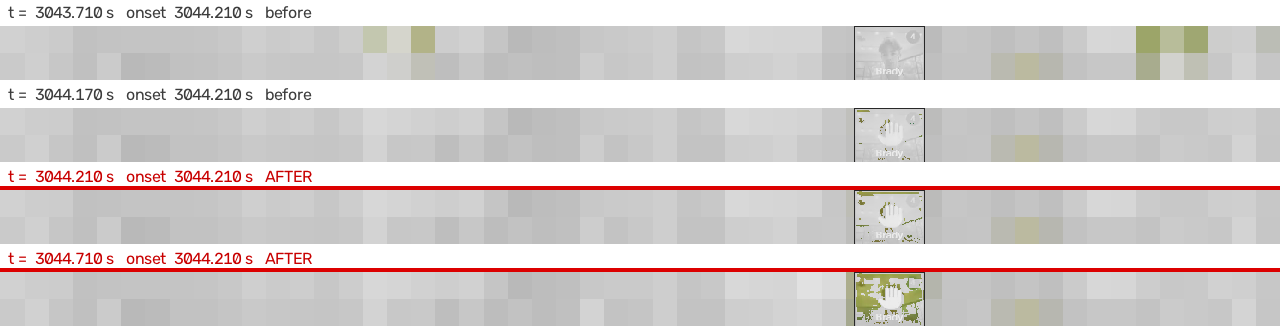

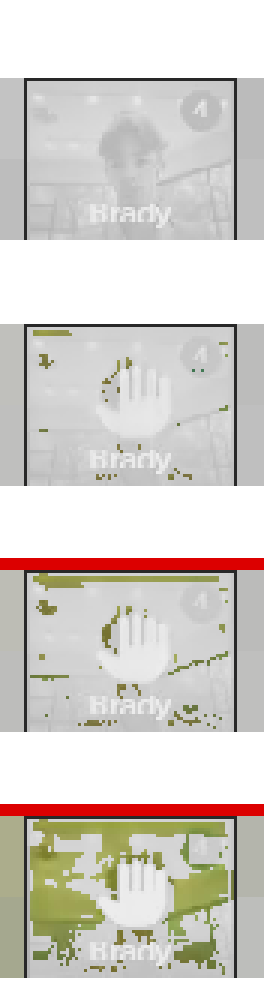

In [7]:
from IPython.display import Image
display(Image(filename="docs/img/audit_raise_86380.png"))
display(Image(filename="docs/img/audit_raise_86380_tile.png", width=420))

**Figure 1.1. One raise, frame by frame (test session 86380).** Top: four frames of the tile
strip, 0.5 s and 0.04 s before the re-timed onset, at the onset, and 0.5 s after (the red bar
marks the frames counted as hand up). Bottom: my tile from the same four frames, enlarged.
Classmates' tiles and names are pixelated.

### 1.6 Moments and labels

The prediction task lives on a grid: **every 2 seconds** of every class is a moment *t*.
A moment *counts* (`at_risk`) when a raise could start then and its label can be trusted
(hand down, not just lowered, not speaking, main room, my tile visible, class passed QA).
The headline label `y_H15_g2` = 1 when my hand goes up in (t + 2 s, t + 15 s].

In [8]:
points = pd.read_parquet(TABLES / "points.parquet")
points = points[points["class_id"].isin(kept["class_id"])].merge(kept[["class_id", "split"]], on="class_id")
risk = points[points["at_risk"].astype(bool)]
grid = pd.DataFrame({
    "moments": points.groupby("split").size(),
    "counting": risk.groupby("split").size(),
    "positive": risk.groupby("split")["y_H15_g2"].apply(lambda s: int((s == 1).sum())),
})
grid["positive_share"] = (grid["positive"] / grid["counting"]).map("{:.2%}".format)
display(grid.loc[["train", "validation", "test"]])
why = points.loc[~points["at_risk"].astype(bool), "excl_reason"].value_counts(normalize=True)
print("why moments do not count:", (why.head(8) * 100).round(1).to_dict())

,moments,counting,positive,positive_share
split,,,,
train,866766,385063,5524,1.43%
validation,279399,117372,1778,1.51%
test,281707,125644,1904,1.52%


why moments do not count: {'breakout': 40.5, 'unobservable': 36.9, 'hand_up': 6.9, 'me_speaking': 4.6, 'opening': 3.6, 'class_qa': 3.3, 'break': 2.3, 'post_lowering': 1.2}


### 1.7 Pre-class work and class content

Harvested from Forum and the SLE workbook site: each class's learning outcomes and study
guide, and my pre-class workbook, **rebuilt as it stood at class start** by replaying its
revision history (`oncue/sharedb.py`), so no edit made during or after class leaks in.

In [9]:
pcw_status = pd.read_parquet(TABLES / "pcw_status.parquet")
pcw_status = pcw_status[pcw_status["class_id"].isin(kept["class_id"])].merge(
    kept[["class_id", "split"]], on="class_id")
display(pd.crosstab(pcw_status["split"], pcw_status["pcw_status"]).loc[["train", "validation", "test"]])
blocks = pd.read_parquet(TABLES / "pcw_blocks.parquet")
asof = blocks[blocks["class_id"].isin(pcw_status.loc[pcw_status["pcw_status"] == "asof_start", "class_id"])]
print(f"workbooks as of class start: {asof['class_id'].nunique()} | blocks: {len(asof)} | "
      f"answered before class: {int((asof['answer_words'] > 0).sum())} | "
      f"median words per workbook: {int(asof.groupby('class_id')['answer_words'].sum().median())}")

pcw_status,asof_start,empty,none,unknown
split,,,,
train,200,8,80,1
validation,61,2,31,0
test,64,2,28,0


workbooks as of class start: 325 | blocks: 3943 | answered before class: 1423 | median words per workbook: 260


### 1.8 Text frames and their embeddings

The transcript is cut into short *frames* (at every pause of 0.4 s or 5 s of speech), names
masked and text normalised. Each frame becomes a 384-number vector with the sentence encoder
`BAAI/bge-small-en-v1.5`: texts with similar meaning get similar vectors. Every model uses
these same vectors.

In [10]:
frames = pd.read_parquet(TABLES / "frames.parquet", columns=["class_id", "close_s", "role", "n_words"])
frames = frames[frames["class_id"].isin(kept["class_id"])]
print(f"{len(frames):,} frames over {frames['class_id'].nunique()} classes;",
      "by role:", frames["role"].value_counts().to_dict())
meta_p = TABLES / "frames_emb.json"
if meta_p.exists():
    print("encoder:", json.loads(meta_p.read_text()))

512,381 frames over 474 classes; by role: {'prof': 340923, 'student': 148626, 'me': 18514, 'unk': 4318}
encoder: {'model': 'BAAI/bge-small-en-v1.5', 'n': 512381, 'dim': 384}


### 1.9 The model inputs (one row per moment)

76 numbers per moment, all computed only from what was known at that moment: class context,
who is talking, my participation and raise history so far, polls, open questions, the words
of the last 15/60 s, and how close the talk is to the class material and to my pre-class
work. Plus four pooled text vectors per moment (last 15 s, last 60 s, last utterance, the
professor's last utterance) in `features_emb.npy`.

In [11]:
fp = TABLES / "features.parquet"
if fp.exists():
    features = pd.read_parquet(fp)
    features = features[features["class_id"].isin(kept["class_id"])]
    inputs = [c for c in features.columns if c not in ("class_id", "t_s", "emb_row")]
    print(f"{len(features):,} moments x {len(inputs)} inputs")
    groups = pd.Series([c.split("_")[0] for c in inputs]).value_counts()
    display(groups.rename("inputs").to_frame().T)
    if (TABLES / "features_emb.npy").exists():   # 4.4 GB: local only, not in the Drive data
        emb = np.load(TABLES / "features_emb.npy", mmap_mode="r")
        print("pooled text vectors:", emb.shape, emb.dtype)
    else:
        print("pooled text vectors: features_emb.npy is not in the shared data (4.4 GB); "
              "Part 3 reads the saved results, so it is not needed")
else:
    print("features.parquet not built yet (run `python -m oncue features --split all`)")

1,427,872 moments x 76 inputs


,ctx,pcw,spk,me,q,poll,n,wpm,filler,frac,topic,own,lo,sg,has
inputs,22,14,10,10,6,4,2,1,1,1,1,1,1,1,1


pooled text vectors: (1427872, 1536) float16


### 1.10 The content vector store (semantic map of me)

Only my own words and the course material: learning outcomes, study guide paragraphs,
workbook prompts, my workbook answers as of class start, and everything I said in class,
each tagged with class, course, subject, term and date. A moment may only use items that
existed before it.

In [12]:
vp = DATA_DIR / "vectors"
if (vp / "items.parquet").exists():
    items = pd.read_parquet(vp / "items.parquet", columns=["class_id", "course_area", "kind", "n_words"])
    vecs = np.load(vp / "embeddings.npy", mmap_mode="r")
    print(f"{len(items):,} items, vectors {vecs.shape}")
    display(pd.crosstab(items["kind"], items["course_area"]))
else:
    print("vector store not built yet (run `python -m oncue vectors --split all`)")

33,354 items, vectors (33354, 384)


course_area,B,CS,other
kind,,,
learning_outcome,706,524,729
my_utterance,9475,2699,6250
pcw_answer,205,1083,613
pcw_prompt,112,2164,698
study_guide,1964,1053,5079


### 1.11 Summary

In [13]:
overview = pd.DataFrame({
    "classes": kept.groupby("split").size(),
    "qa_pass": qa["qa_pass"],
    "raises": summary["raises"],
    "moments_counting": grid["counting"],
    "positive_moments": grid["positive"],
    "workbooks_asof_start": pcw_status[pcw_status["pcw_status"] == "asof_start"].groupby("split").size(),
}).loc[["train", "validation", "test"]]
overview.loc["total"] = overview.sum()
display(overview.astype(int))

,classes,qa_pass,raises,moments_counting,positive_moments,workbooks_asof_start
split,,,,,,
train,289,274,1674,385063,5524,200
validation,94,86,541,117372,1778,61
test,94,86,559,125644,1904,64
total,477,446,2774,628079,9206,325


## 2. Naive models

**What a model does.** Every 2 s of class, the model looks back at the class so far and gives
one number: the probability that my hand goes up in the next 2-15 s. The naive models look
back at very little:

| model | what it looks back at |
|---|---|
| Base rate | nothing: always the share of positive moments in train (0.014) |
| Professor-question rule | the professor's last question: is it still open, and how many seconds ago was it asked? A fixed formula, nothing learned |
| Question timing (logistic regression) | the same question facts; the shape of "how soon after a question" is learned from train |
| Naive Bayes | the words said in the last 60 s (tagged professor / student / me) |
| TF-IDF + logistic regression | the same words, each weighted by how distinctive it is |

The professor-question rule is a fixed formula: its score is highest right after the
professor asks a question or opens the floor ("any thoughts?") and fades within about 10-20 s.
Each model's math is in the write-up (Models, N1-N5).

**From probability to a guess.** At every counting moment, if the model's probability is at or
above its **threshold**, the model says "my hand goes up in the next 2-15 s" (a yes moment).
There is no cooldown: it may say yes at every moment. Back-to-back yes moments are one
**warning**. The threshold is fixed on the **train** classes so the
model says yes as often as the truth is yes there (as many yes moments as positive moments, about
1.4% of moments), then frozen for validation and test.

**Scoring: only the warnings.** A warning is **right** if my hand went up 2-15 s after one of
its moments and **wrong** if it did not. What each number in the tables means:

| number | what it measures | good is |
|---|---|---|
| threshold | the probability at which the model starts guessing; fixed on train so it says yes as often as the truth is yes there | (a setting, not a score) |
| yes moment | a 2-s moment at or above the threshold: the model says "my hand goes up in the next 2-15 s" | |
| warnings | one unbroken run of yes moments counts as one warning (counting only: the model may still say yes at every moment) | (a count) |
| right / wrong | warnings followed / not followed by my raise 2-15 s after one of their moments | more right, fewer wrong |
| % right | right ÷ warnings: when it warns, how often it is right. A random one-moment guess: 1.5% | high |
| warnings per class | warnings ÷ classes. I raise about 6 times per class; a perfect model makes about 4 (one per raise it can see) | near the perfect model |
| raises warned (a guess 2-15 s ahead) | of my raises, how many had at least one guess 2-15 s before them (every warning is at least 2 s ahead). "24 of 504" = 24 warned out of all 504 raises. Stops a model looking good by guessing once | high |
| a guess 2-5 s ahead (ideal) | of my raises, how many had a guess 2-5 s before the hand went up: the ideal warning, close enough to be sure and early enough to act | high |
| a guess 5-10 s / 10-15 s ahead | the same for the earlier windows (a raise can count in more than one window) | high |
| perfect model (ceiling row) | a model that guesses exactly at the positive moments. Its "raises warned" is below the total because some raises have no counting moment before them (e.g. my tile could not be read), so no model can warn those | the most any model can reach |
| AP | ranking without any threshold (equation in the write-up, Metrics M1): random = the positive share (0.015), perfect = 1 | high |
| AP within class (AP_w) | the same, ranking each class only against itself: does it know *when* within a class? | high |
| ROC AUC | the chance a random positive moment gets a higher probability than a random negative one: random = 0.5, perfect = 1 | high |

**Ranking, no threshold: average precision.** Sort all moments by probability; at each truly
positive moment take the precision so far; average them. Random = 0.015, perfect = 1.
Within-class AP does the same inside each session, then averages the sessions weighted by their
raises (equations in the write-up, Metrics M1-M2).

Trained on **train**; each model's one setting chosen on **validation**; **test** scored once,
at the end of this part, with everything frozen.

In [14]:
sys.path.insert(0, str(Path.cwd()))          # the oncue package lives next to this notebook
import pickle
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from oncue import baselines

data = baselines.load(TABLES, DATA_DIR / "03_split" / "split.csv")
raises = baselines.onsets(TABLES, data["class_id"].unique())
tr, va, te = (data[data["split"] == s] for s in ("train", "validation", "test"))
display(data.groupby("split").agg(moments=("y", "size"), positives=("y", "sum"),
                                  base_rate=("y", "mean"), classes=("class_id", "nunique"))
        .loc[["train", "validation", "test"]])

RETRAIN = False                              # True: train again; False: reuse the saved models
saved = DATA_DIR / "results" / "naive_models.pkl"
if RETRAIN or not saved.exists():
    results, fitted = baselines.run(data, raises)
    saved.parent.mkdir(exist_ok=True)
    with open(saved, "wb") as fh:
        pickle.dump({"results": results, "fitted": fitted}, fh)
else:
    with open(saved, "rb") as fh:
        loaded = pickle.load(fh)
    results, fitted = loaded["results"], loaded["fitted"]
    print("reusing the saved models:", saved)
IDS = [i for i in results["id"] if i != "B0"]
NAME = dict(baselines.NAMES)
P_TR = {i: fitted[i][1] for i in fitted}
P_VA = {i: fitted[i][2] for i in fitted}
TAU = {i: baselines.tau_like_truth(tr["y"], P_TR[i]) for i in IDS}   # yes as often as the truth, on train
display(pd.DataFrame({"threshold (from train)": TAU}).rename(index=NAME).round(4))

,moments,positives,base_rate,classes
split,,,,
train,385063,5524,0.014346,274
validation,117372,1778,0.015148,86
test,125644,1904,0.015154,86


reusing the saved models: /Users/brady/cs156-ml/pipeline1/data/results/naive_models.pkl


,threshold (from train)
Professor-question rule,0.4691
Question timing (LR),0.0304
Naive Bayes (words),1.0000
TF-IDF + LR (words),0.0322


In [15]:
EX = int(raises[raises["class_id"].isin(va["class_id"])].groupby("class_id").size().idxmax())

def guess_row(frame, p, tau):
    s = baselines.guess_scores(frame, p, tau, raises)
    return {"warnings": s["warnings"], "right": s["warnings_right"], "wrong": s["warnings_wrong"],
            "% right": f"{100 * s['pct_warnings_right']:.1f}%" if s["warnings"] else "-",
            "warnings per class": round(s["warnings_per_class"], 1),
            "raises warned (a guess 2-15 s ahead)": f"{s['raises_warned']} of {s['raises']}",
            "a guess 2-5 s ahead (ideal)": s["warned_2_5"], "a guess 5-10 s ahead": s["warned_5_10"],
            "a guess 10-15 s ahead": s["warned_10_15"]}

def perfect_row(frame):
    # a perfect model guesses exactly at the positive moments: the ceiling for every column
    return guess_row(frame, frame["y"].to_numpy(float), 0.5)

def guess_table(frame, preds, taus, ids):
    rows = {NAME[i]: guess_row(frame, preds[i], taus[i]) for i in ids}
    rows["A perfect model (ceiling)"] = perfect_row(frame)
    rows["A random one-moment guess (reference)"] = {k: "" for k in rows["A perfect model (ceiling)"]}
    rows["A random one-moment guess (reference)"]["% right"] = f"{100 * frame['y'].mean():.1f}%"
    return pd.DataFrame(rows).T

def with_gaps(t, q):
    # break the line where moments stop counting (my hand up, me speaking, breakouts)
    cut = np.flatnonzero(np.diff(t) > 2.5) + 1
    return np.insert(t.astype(float), cut, np.nan), np.insert(q.astype(float), cut, np.nan)

def show_model(i, frame, p, tau, split_name="validation"):
    pr = baselines.peri_raise(frame, p, raises)
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
    a.plot(pr["offset_s"], pr["mean_p"], lw=2, color="tab:blue", label="average before my raises")
    a.axhline(p.mean(), color="grey", ls="--", lw=1, label="its normal level (all moments)")
    a.axhline(tau, color="tab:red", ls=":", lw=1.5, label="guess line (threshold)")
    a.axvspan(-2, 0, color="grey", alpha=0.15)
    a.set(xlabel="seconds before my raise", ylabel="probability of a raise in the next 2-15 s",
          title=f"The minute before my raises ({frame['class_id'].nunique()} {split_name} classes)")
    a.legend(fontsize=8)
    mask = (frame["class_id"] == EX).to_numpy()
    c, q = frame[mask], p[mask]
    said = q >= tau
    on = raises.loc[raises["class_id"] == EX, "onset_s"].to_numpy()
    x, yq = with_gaps(c["t_s"].to_numpy(), q)
    b.plot(x / 60, yq, lw=0.7, color="tab:blue")
    b.axhline(tau, color="tab:red", ls=":", lw=1.5)
    for o in on:
        b.axvline(o / 60, color="green", alpha=0.6, lw=1.2)
    b.plot(c["t_s"].to_numpy()[said] / 60, q[said], "o", color="tab:red", ms=3)
    s = baselines.guess_scores(c, q, tau, raises)
    b.set(xlabel=f"minute of class {EX}", ylabel="probability",
          title=f"One class: {s['warnings']} warnings ({s['warnings_right']} right), {len(on)} raises, {s['raises_warned']} warned")
    fig.suptitle(NAME[i], fontweight="bold")
    plt.tight_layout(); plt.show()
    display(pd.DataFrame({NAME[i]: guess_row(frame, p, tau), "A perfect model (ceiling)": perfect_row(frame)}).T)

def all_together(frame, preds, ids, title):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i in ids:
        pr = baselines.peri_raise(frame, preds[i], raises)
        ax.plot(pr["offset_s"], pr["mean_p"] / preds[i].mean(), lw=1.8, label=NAME[i])
    ax.axhline(1, color="grey", ls="--", lw=1, label="normal (no change)")
    ax.axvspan(-2, 0, color="grey", alpha=0.15)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.set(xlabel="seconds before my raise", ylabel="× its normal level", title=title)
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

### 2.1 Professor-question rule

Looks back at the professor's last question only: high right after it is asked (and while it stays open), fading with a 10 s time constant. Nothing is learned.

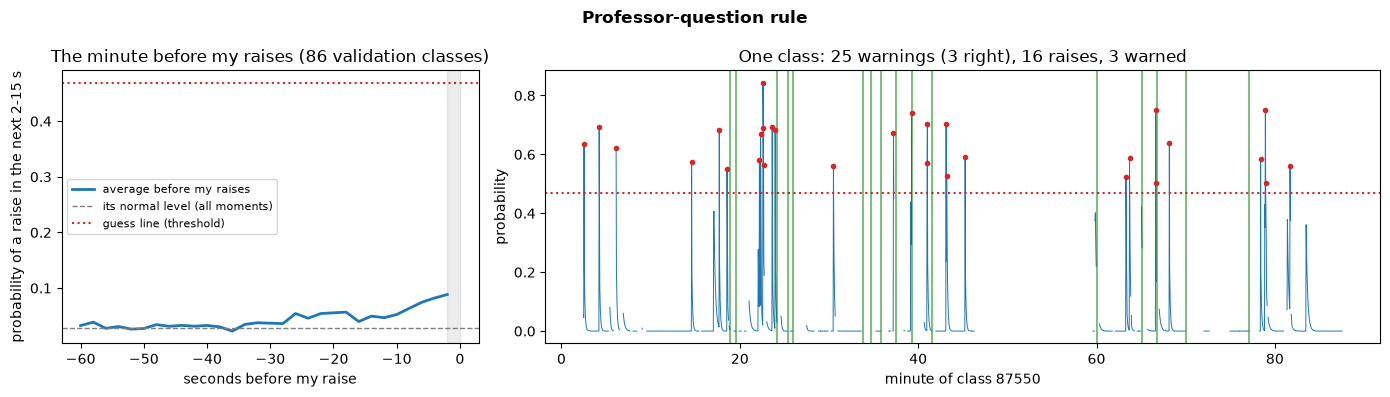

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Professor-question rule,1276,43,1233,3.4%,14.8,37 of 504,19,18,13
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [16]:
show_model("R", va, P_VA["R"], TAU["R"])

**Figure 2.1. Professor-question rule on validation.** **Left:** the model's average probability at each second of the minute before my raises (blue), against its average over all moments (grey dashed) and its threshold (red dotted); a model that sees a raise coming climbs towards the red line. The shaded last 2 s are not scored. **Right:** the same model through one validation class (the one with the most raises): blue = its probability (gaps = moments that do not count), red dots = its yes moments (a run of dots is one warning), green lines = my raises. The table counts its warnings on all validation classes, with a perfect model as the ceiling.

### 2.2 Question timing (logistic regression)

Looks back at the same question facts: is a question open, seconds since it was asked, seconds since an open invitation, kind of question. It learns from train how my chance of raising changes with those seconds.

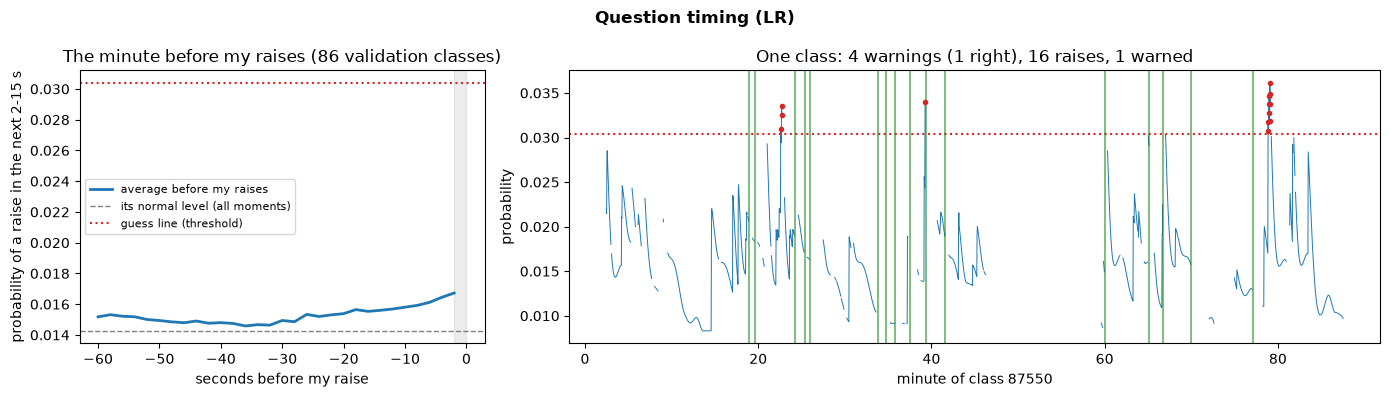

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Question timing (LR),431,27,404,6.3%,5.0,24 of 504,19,15,13
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [17]:
show_model("QT", va, P_VA["QT"], TAU["QT"])

**Figure 2.2. Question timing on validation.** **Left:** the model's average probability at each second of the minute before my raises (blue), against its average over all moments (grey dashed) and its threshold (red dotted); a model that sees a raise coming climbs towards the red line. The shaded last 2 s are not scored. **Right:** the same model through one validation class (the one with the most raises): blue = its probability (gaps = moments that do not count), red dots = its yes moments (a run of dots is one warning), green lines = my raises. The table counts its warnings on all validation classes, with a perfect model as the ceiling.

### 2.3 Naive Bayes (words)

Looks back at the words said in the last 60 s, each tagged with who said it (professor, a student, me), and asks which words appear more often just before my raises.

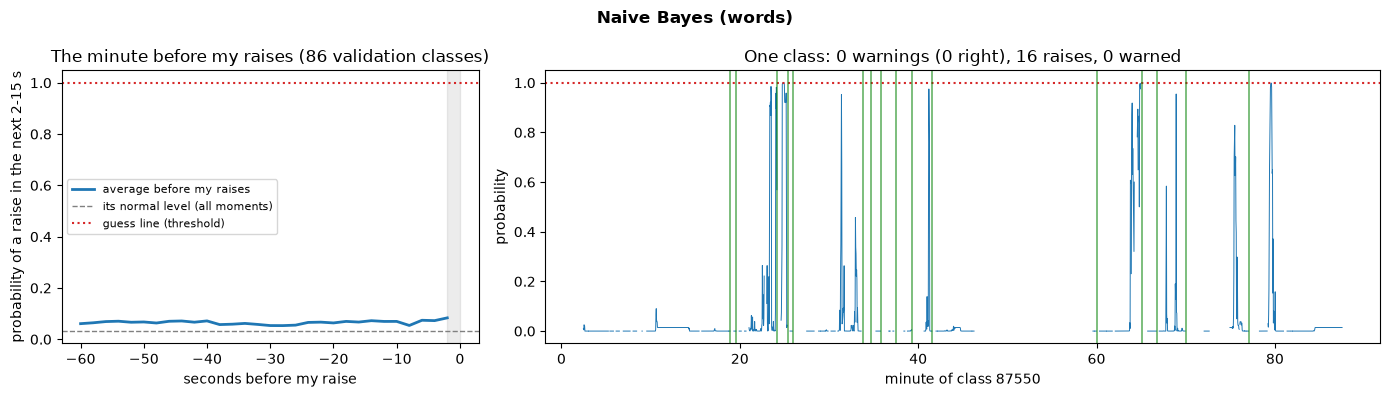

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Naive Bayes (words),25,1,24,4.0%,0.3,1 of 504,1,1,0
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [18]:
show_model("NB", va, P_VA["NB"], TAU["NB"])

**Figure 2.3. Naive Bayes on validation.** **Left:** the model's average probability at each second of the minute before my raises (blue), against its average over all moments (grey dashed) and its threshold (red dotted); a model that sees a raise coming climbs towards the red line. The shaded last 2 s are not scored. **Right:** the same model through one validation class (the one with the most raises): blue = its probability (gaps = moments that do not count), red dots = its yes moments (a run of dots is one warning), green lines = my raises. The table counts its warnings on all validation classes, with a perfect model as the ceiling.

### 2.4 TF-IDF + logistic regression (words)

Looks back at the same 60 s of words, each weighted by how distinctive it is, and learns a weight per word.

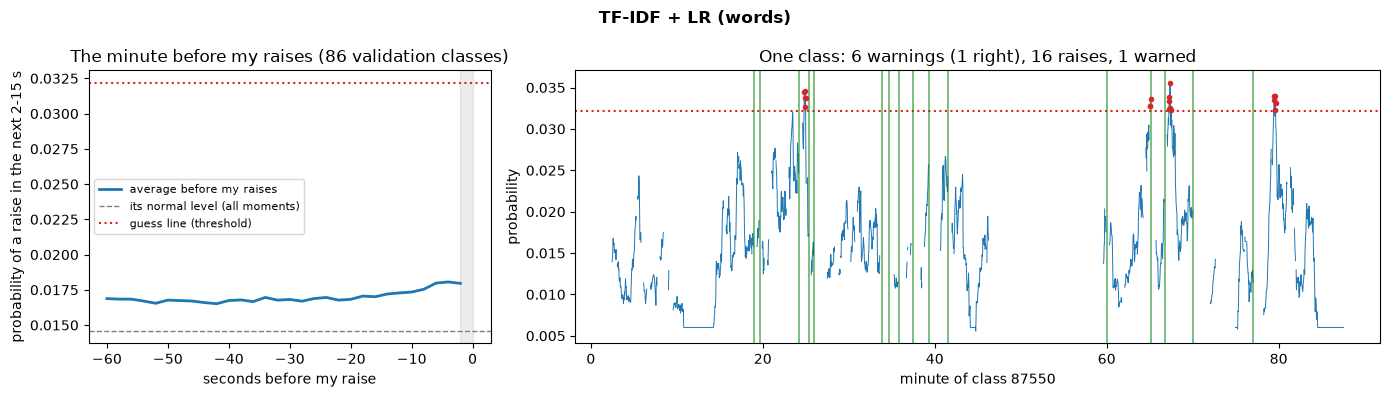

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
TF-IDF + LR (words),207,11,196,5.3%,2.4,10 of 504,8,6,6
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [19]:
show_model("TFIDF", va, P_VA["TFIDF"], TAU["TFIDF"])

**Figure 2.4. TF-IDF + LR on validation.** **Left:** the model's average probability at each second of the minute before my raises (blue), against its average over all moments (grey dashed) and its threshold (red dotted); a model that sees a raise coming climbs towards the red line. The shaded last 2 s are not scored. **Right:** the same model through one validation class (the one with the most raises): blue = its probability (gaps = moments that do not count), red dots = its yes moments (a run of dots is one warning), green lines = my raises. The table counts its warnings on all validation classes, with a perfect model as the ceiling.

### 2.5 All naive models together (validation)

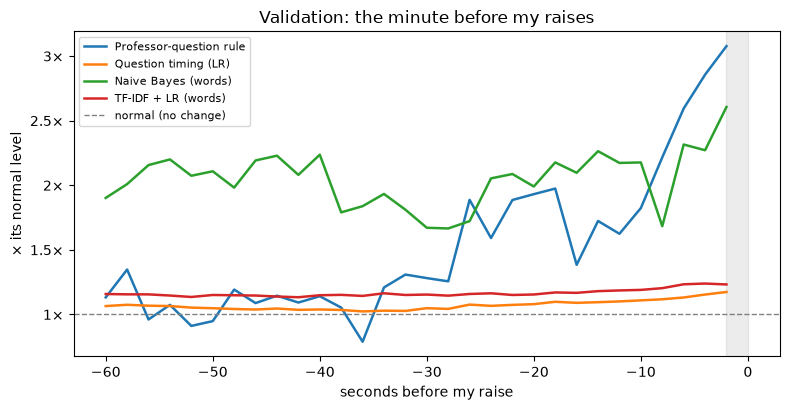

In [20]:
all_together(va, P_VA, IDS, "Validation: the minute before my raises")

**Figure 2.5. All naive models before my raises (validation).** For each model: its average
probability at each second before my raises, divided by its own average over all moments, so
models on different scales can share one axis. 1× = no change (the model notices nothing); 2× =
twice as sure as usual that a raise is coming.

In [21]:
display(Markdown("**Warnings on validation** (threshold from train: yes as often as the truth)"))
display(guess_table(va, P_VA, TAU, IDS))
display(Markdown("**Ranking on validation** (no threshold)"))
display(results[["model", "setting", "AP", "AP_w", "ROC_AUC", "base_rate"]].round(4))

**Warnings on validation** (threshold from train: yes as often as the truth)

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Professor-question rule,1276,43,1233,3.4%,14.8,37 of 504,19,18,13
Question timing (LR),431,27,404,6.3%,5.0,24 of 504,19,15,13
Naive Bayes (words),25,1,24,4.0%,0.3,1 of 504,1,1,0
TF-IDF + LR (words),207,11,196,5.3%,2.4,10 of 504,8,6,6
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270
A random one-moment guess (reference),,,,1.5%,,,,,


**Ranking on validation** (no threshold)

,model,setting,AP,AP_w,ROC_AUC,base_rate
0,Base rate,NaN,0.0151,0.0220,0.5000,0.0151
1,Professor-question rule,NaN,0.0245,0.0502,0.5995,0.0151
2,Question timing (LR),10.0,0.0231,0.0493,0.5881,0.0151
3,Naive Bayes (words),1.0,0.0174,0.0370,0.5068,0.0151
4,TF-IDF + LR (words),0.1,0.0242,0.0516,0.6575,0.0151


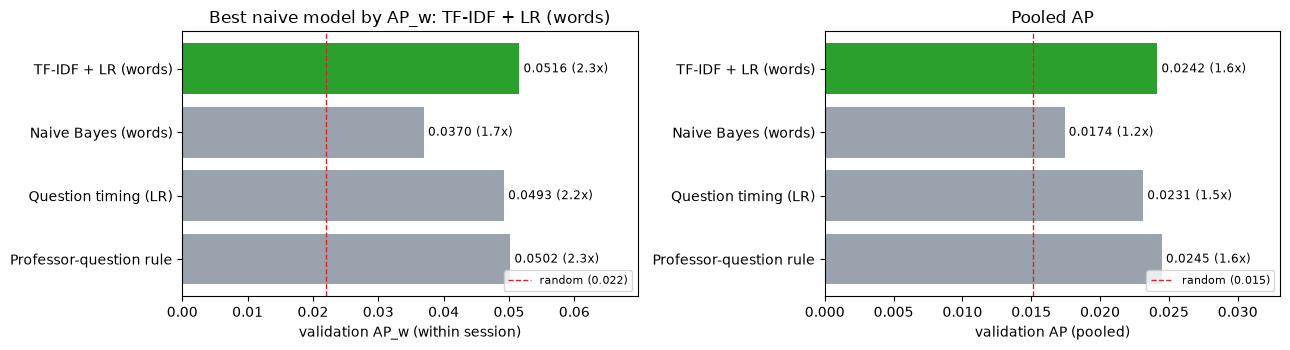

In [22]:
from oncue import metrics as ometrics
r_ = results.set_index("id").loc[IDS]
rand_w = ometrics.ap_within(va["y"].to_numpy(), np.full(len(va), 0.5), va["class_id"].to_numpy())
best_n = r_["AP_w"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, col, rnd in ((axes[0], "AP_w", rand_w), (axes[1], "AP", va["y"].mean())):
    ax.barh([NAME[i] for i in IDS], r_[col], color=["tab:green" if i == best_n else "#9aa3ad" for i in IDS])
    ax.axvline(rnd, color="tab:red", ls="--", lw=1, label=f"random ({rnd:.3f})")
    for k, v in enumerate(r_[col]):
        ax.text(v, k, f" {v:.4f} ({v / rnd:.1f}x)", va="center", fontsize=8.5)
    ax.set(xlabel=f"validation {col}" + (" (within session)" if col == "AP_w" else " (pooled)"),
           xlim=(0, r_[col].max() * 1.35))
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_title(f"Best naive model by AP_w: {NAME[best_n]}")
axes[1].set_title("Pooled AP")
plt.tight_layout(); plt.show()

**Figure 2.6. The naive models compared (validation).** Left: within-session AP (the headline);
right: pooled AP; the red dashed line is a model with no information. Green: the best naive model
by within-session AP. Within sessions they sit between 1.7x and 2.3x random: the floor the flexible
models in Part 3 have to beat.

### 2.6 Test: the frozen naive models, scored once

Nothing below changes any model: settings come from validation, thresholds from train.

**Ranking: validation vs test**

,validation AP,test AP,test AP_w,test ROC AUC
Base rate,0.0151,0.0152,0.0249,0.5000
Professor-question rule,0.0245,0.0246,0.0510,0.6196
Question timing (LR),0.0231,0.0263,0.0632,0.6207
Naive Bayes (words),0.0174,0.0196,0.0483,0.5358
TF-IDF + LR (words),0.0242,0.0268,0.0609,0.6598


**Warnings on test**

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Professor-question rule,1537,50,1487,3.3%,17.9,46 of 533,15,23,16
Question timing (LR),505,35,470,6.9%,5.9,30 of 533,19,15,19
Naive Bayes (words),21,1,20,4.8%,0.2,1 of 533,0,1,0
TF-IDF + LR (words),267,12,255,4.5%,3.1,11 of 533,9,9,6
A perfect model (ceiling),323,323,0,100.0%,3.8,322 of 533,314,309,290
A random one-moment guess (reference),,,,1.5%,,,,,


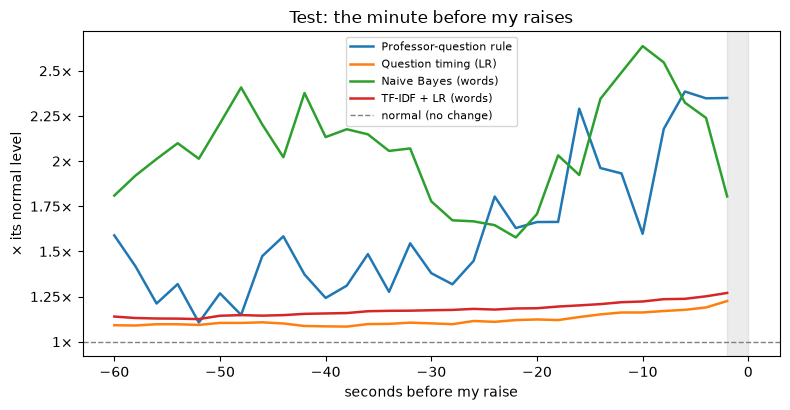

In [23]:
P_TE = {i: baselines.proba(fitted[i][0], te) for i in fitted}
rank = pd.DataFrame({"validation AP": results.set_index("id")["AP"],
                     "test AP": {i: baselines.point_metrics(te, P_TE[i])["AP"] for i in fitted},
                     "test AP_w": {i: baselines.point_metrics(te, P_TE[i])["AP_w"] for i in fitted},
                     "test ROC AUC": {i: baselines.point_metrics(te, P_TE[i])["ROC_AUC"] for i in fitted}})
rank.index = [NAME[i] for i in rank.index]
display(Markdown("**Ranking: validation vs test**"))
display(rank.round(4))
display(Markdown("**Warnings on test**"))
display(guess_table(te, P_TE, TAU, IDS))
all_together(te, P_TE, IDS, "Test: the minute before my raises")

**Figure 2.7. All naive models before my raises (test).** As Figure 2.5, on the 86 test classes
with the models and thresholds frozen.

## 3. Flexible models

The naive models each read one thing. The flexible pipeline reads everything, one step at a
time: **gradient-boosted trees** make the final prediction, and each specialist adds one score
to the trees' inputs.

```
inputs at moment t (only the past)
  ├─ 68 numbers: class context, who is talking, my participation and raise history, polls,
  │              questions, words per minute, similarity to the class material, pre-class work
  ├─ sentence vectors: the professor's latest words, the last 60 s, the class material,
  │                    my pre-class answers (as of class start), my own earlier words
  │
  ├─ 3.2 content-alignment MLP ──────────► score ─┐
  ├─ 3.3 TCN                       ──────► score ─┤
  ├─ fine-tuned transformer (later) ─────► score ─┤
  │                                                ▼
  └─ 3.1 gradient-boosted trees: the 68 numbers + the scores → P(raise in the next 2-15 s)
```

Section 3.4 tests the same specialists **without the trees** (simpler combiners), 3.5
compares everything with error bars, 3.6 shows how the final pipeline learned, 3.7 scores test
once, and 3.8 follows one test session from start to end.

**Rules that keep it honest.**

* **Out-of-fold (OOF) scores.** The 274 train classes are split into 4 groups (every class's
  moments in one group). Each model is trained 4 times, each time on 3 groups, and scores the
  group it did not see. Those honest train scores are what the trees learn from, and what the
  guess threshold is set on. Each validation session is scored by **one** of the
  same 4 fold models (assigned round-robin), so a validation score is made exactly like a
  train score: by a model trained on 3/4 of the train sessions, on a session it never saw.
  (Scores from a fifth model trained on all train sessions sat on a different scale; an
  average of the 4 fold models has a narrower spread; either way a threshold set on the train
  scores then said yes too rarely on validation.) Models trained on all train sessions are
  used only to choose settings.
* **Averaged training runs.** The MLP and the TCN are trained 5 times in every fold (different
  random starts) and the 5 scores averaged, because one run is noisy.
* **Validation decides** every setting (tree size, number of trees, MLP epochs).
* **Test is held back** until the final model is chosen, then scored once.
* **Same scoring as Part 2:** threshold "yes as often as the truth" (on the OOF train scores),
  warnings right / wrong, raises warned, and AP.

In [24]:
import subprocess
from oncue import config as oconfig, flex

RETRAIN_FLEX = False             # True: retrain all of Part 3 (python -m oncue flex --step all)
if RETRAIN_FLEX or not (DATA_DIR / "results" / "flex" / "bootstrap.pkl").exists():
    subprocess.run([sys.executable, "-m", "oncue", "flex", "--step", "all"], check=True)
RES = {k: flex.load_result(k) for k in flex.FLEX_MODELS}
BOOT = flex.load_result("bootstrap")

FX = flex.load()                 # Part 3's rows: the same moments, in the same order, as Part 2's
for s, frame in (("train", tr), ("validation", va)):
    assert (FX.loc[FX["split"] == s, ["class_id", "t_s"]].to_numpy() == frame[["class_id", "t_s"]].to_numpy()).all()
for k, name in (("gbt", "GBT (trees)"), ("mlp", "Content-alignment MLP"), ("gbt_mlp", "GBT + MLP"),
                ("tcn", "TCN"), ("gbt_mlp_tcn", "GBT + MLP + TCN"),
                ("mlp_tcn_lr", "MLP + TCN, no trees (logistic)"), ("lr_all", "Logistic combiner (all inputs)")):
    NAME[k] = name
    P_TR[k], P_VA[k] = RES[k]["oof"], RES[k]["val"]
    TAU[k] = baselines.tau_like_truth(tr["y"], P_TR[k])     # on the out-of-fold train scores
print("thresholds (from OOF train scores):", {NAME[k]: round(TAU[k], 4) for k in RES})

thresholds (from OOF train scores): {'GBT (trees)': 0.05, 'Content-alignment MLP': 0.0503, 'GBT + MLP': 0.0704, 'TCN': 0.0462, 'GBT + MLP + TCN': 0.069, 'MLP + TCN, no trees (logistic)': 0.0407, 'Logistic combiner (all inputs)': 0.0569}


### 3.1 Gradient-boosted trees

**What it reads:** the 68 structured inputs at moment t (table below). Left out: `has_qmark`
(the transcriber's punctuation may use words after t), `spk_cur_in_my_group` (breakout
groups are not parsed, always empty), `ctx_n_present` (presence is not parsed) and the 5 spline
copies of the class minute (trees do not need them).

**The model.** A sum of small regression trees, each one fitted to what the trees before it
still get wrong, shrunk by a learning rate (scikit-learn's HistGradientBoosting: learning rate
0.05, L2 penalty 1, 80% of inputs per split, categories handled natively). Three tree sizes
were tried with up to 600 trees each; validation AP picked the size and the number of trees.
The math is in the write-up (Models, F1).

,inputs
input group,
class context,16
my pre-class work (as of class start),11
who is talking,9
"words (counts, pace, topic shift, similarity to my words)",7
my participation,6
questions,6
"class material (pre-class template, learning outcomes, study guide)",5
my raise history,4
polls,4


chosen on validation: 15 leaves per tree, 80 trees; validation AP of the 4 fold models: 0.0261


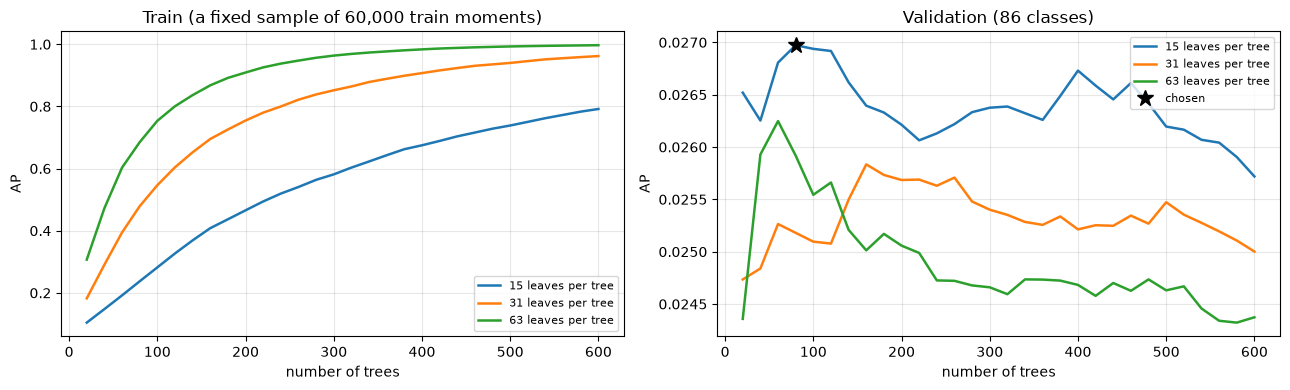

In [25]:
g = RES["gbt"]
groups = pd.Series([oconfig.feature_group(c) for c in g["inputs"]]).value_counts()
GROUP_NAMES = {"ctx": "class context", "spk": "who is talking", "me": "my participation",
               "me_hand": "my raise history", "poll": "polls", "q": "questions",
               "text": "words (counts, pace, topic shift, similarity to my words)",
               "pcwT": "class material (pre-class template, learning outcomes, study guide)",
               "pcwA": "my pre-class work (as of class start)"}
display(pd.DataFrame({"inputs": groups}).rename(index=GROUP_NAMES).rename_axis("input group"))
from sklearn.metrics import average_precision_score
def chosen(k):
    c = RES[k]["choice"]
    print(f"chosen on validation: {c['setting']['max_leaf_nodes']} leaves per tree, {c['trees']} trees; "
          f"validation AP of the 4 fold models: {average_precision_score(va['y'], P_VA[k]):.4f}")
chosen("gbt")

cur = g["curve"]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
for k, grp in cur.groupby("setting"):
    lab = f"{grp['max_leaf_nodes'].iloc[0]} leaves per tree"
    a.plot(grp["trees"], grp["train_AP"], lw=1.8, label=lab)
    b.plot(grp["trees"], grp["val_AP"], lw=1.8, label=lab)
b.plot([g["choice"]["trees"]], [g["choice"]["val_AP"]], "k*", ms=12, label="chosen")
a.set(xlabel="number of trees", ylabel="AP", title="Train (a fixed sample of 60,000 train moments)")
b.set(xlabel="number of trees", ylabel="AP", title="Validation (86 classes)")
for ax in (a, b):
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Figure 3.1. Learning curves of the trees.** Average precision as trees are added, for the
three tree sizes. **Left:** on train moments the trees have already seen, AP keeps rising
(the trees memorise train). **Right:** on validation classes they have not seen; the star marks
the size and number of trees with the best validation AP, which is the setting kept (the 4
fold models are then trained with it).

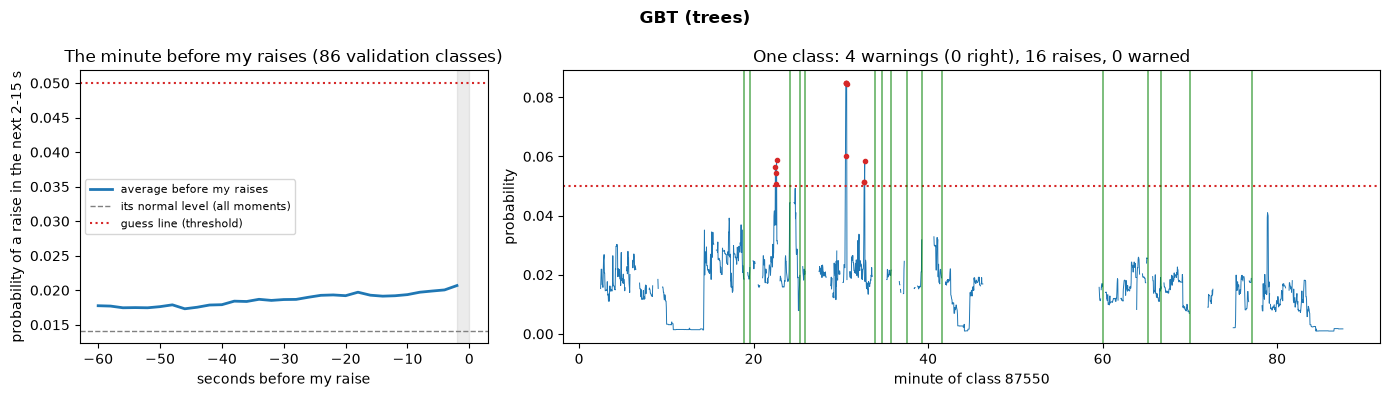

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
GBT (trees),233,9,224,3.9%,2.7,8 of 504,5,5,6
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [26]:
show_model("gbt", va, P_VA["gbt"], TAU["gbt"])

**Figure 3.2. The trees on validation.** As Figure 2.1: **left**, the trees' average
probability in the minute before my raises against its normal level and its threshold;
**right**, the same validation class as in Part 2 (red dots = yes moments, a run of dots
is one warning; green lines = my raises). The table counts its warnings on all validation
classes, with a perfect model as the ceiling.

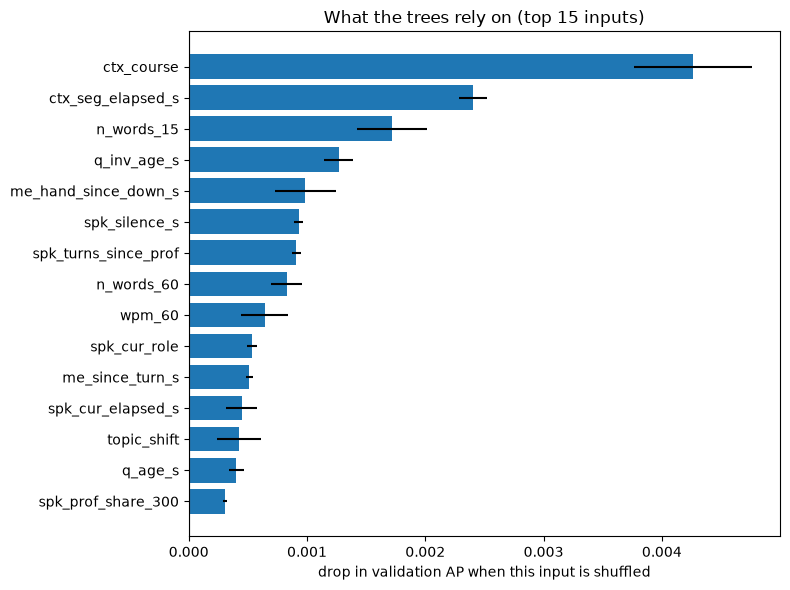

In [27]:
def importance_chart(res, title, top=15, highlight=()):
    imp = res["importance"].head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * top + 1.2))
    colors = ["tab:orange" if c in highlight else "tab:blue" for c in imp["input"]]
    ax.barh(imp["input"], imp["AP_drop"], xerr=imp["AP_drop_sd"], color=colors)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set(xlabel="drop in validation AP when this input is shuffled", title=title)
    plt.tight_layout(); plt.show()

importance_chart(RES["gbt"], "What the trees rely on (top 15 inputs)")

**Figure 3.3. What the trees rely on.** Each bar is how much validation AP falls when that one
input is shuffled across moments (mean of 3 shuffles; the whisker is their spread). A long bar
means the trees lean on that input; a bar near 0 means they could do without it. Prefixes:
`ctx_` class context, `spk_` who is talking, `me_` my participation, `me_hand_` my raise
history, `q_` questions, `poll_` polls, `pcw_` pre-class work, `lo_`/`sg_` similarity to the
learning outcomes / study guide.

### 3.2 Content-alignment MLP

**The idea.** Is what is being said right now close to the class material, to what I prepared,
or to what I usually talk about? The MLP reads five sentence vectors (bge-small, 384 numbers
each, all frozen; nothing in the language model is trained):

| vector | what it is | available from |
|---|---|---|
| q | the professor's latest words | when the frame closes, before t |
| w | everything said in the last 60 s | words spoken by t |
| C | the class material: learning outcomes + study guide (class page) | before class |
| A | my pre-class answers, rebuilt as of class start | before class |
| M | my own earlier words: earlier classes + this class before t | before t |

**The model.** One shared projection (384 → 32 numbers) compresses every vector; the network
then looks at how the "now" vectors (q, w) line up with the reference vectors (C, A, M),
dimension by dimension, plus their 7 plain cosine similarities and 5 flags saying which
vectors exist (64 hidden units, dropout 0.2; the math is in the write-up, Models, F2). Trained
with AdamW (learning rate 0.001, weight decay 0.0001, batches of 4,096 moments), output
started at the base rate. Choosing the number of
epochs: 5 training runs on all train sessions, validation AP after every epoch, and the epoch
with the best **average** AP over the 5 runs is kept. Then in each of the 4 folds, 5 runs of
that many epochs are averaged.

parameters: 25,473; chosen: 4 epochs; 5 runs averaged per fold


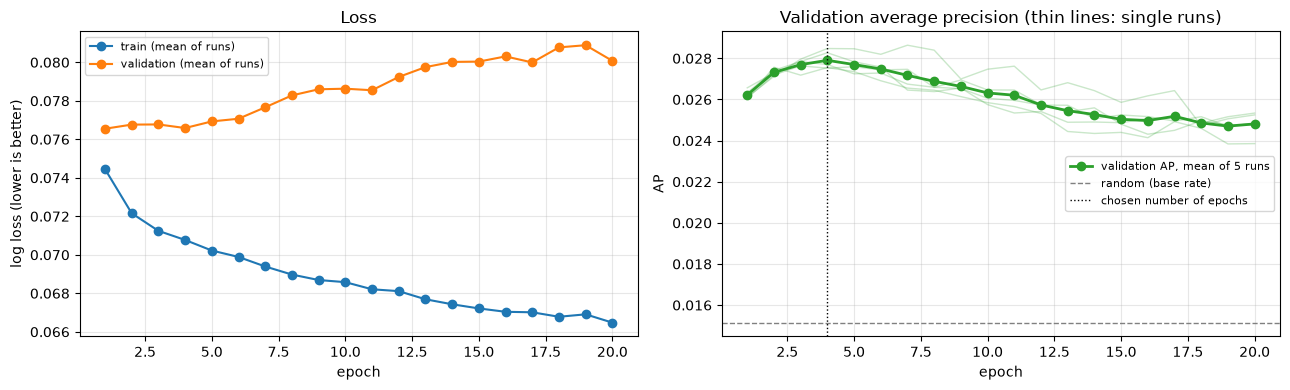

In [28]:
def run_curves(res, ap_col):
    h = res["history"]
    mean = h.groupby("epoch")[["train_loss", "val_loss", ap_col]].mean()
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
    for _, g in h.groupby("run"):
        b.plot(g["epoch"], g[ap_col], color="tab:green", alpha=0.25, lw=1)
    a.plot(mean.index, mean["train_loss"], "o-", label="train (mean of runs)")
    a.plot(mean.index, mean["val_loss"], "o-", label="validation (mean of runs)")
    a.set(xlabel="epoch", ylabel="log loss (lower is better)", title="Loss")
    b.plot(mean.index, mean[ap_col], "o-", color="tab:green", lw=2, label=f"validation AP, mean of {res['n_seeds']} runs")
    b.axhline(va["y"].mean(), color="grey", ls="--", lw=1, label="random (base rate)")
    b.axvline(res["best_epoch"], color="k", ls=":", lw=1, label="chosen number of epochs")
    b.set(xlabel="epoch", ylabel="AP", title="Validation average precision (thin lines: single runs)")
    for ax in (a, b):
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

m = RES["mlp"]
print(f"parameters: {m['n_params']:,}; chosen: {m['best_epoch']} epochs; {m['n_seeds']} runs averaged per fold")
run_curves(m, "val_AP")

**Figure 3.4. Learning curves of the MLP.** **Left:** the log loss after each pass over the
train moments (blue) and on validation (orange), averaged over the 5 runs. **Right:**
validation AP after each epoch: thin lines are single runs, the thick line their average; the
dotted line is the number of epochs kept (the epoch with the best average), the dashed line a
random ranking.

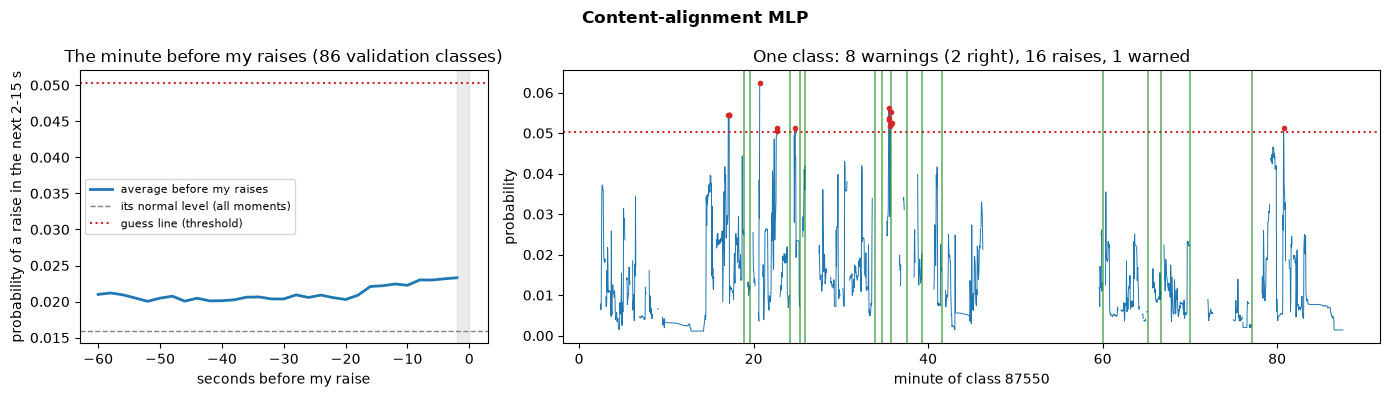

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Content-alignment MLP,572,40,532,7.0%,6.7,36 of 504,23,22,24
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [29]:
show_model("mlp", va, P_VA["mlp"], TAU["mlp"])

**Figure 3.5. The MLP on its own (validation).** As Figure 3.2, for the MLP's probability alone.

### GBT + MLP: the trees with the MLP's score

The trees again, now with 8 more inputs: the MLP's score (out-of-fold on train) and the 7 plain
cosine similarities. Same tree sizes, same choice on validation, same out-of-fold threshold.

chosen on validation: 31 leaves per tree, 240 trees; validation AP of the 4 fold models: 0.0273


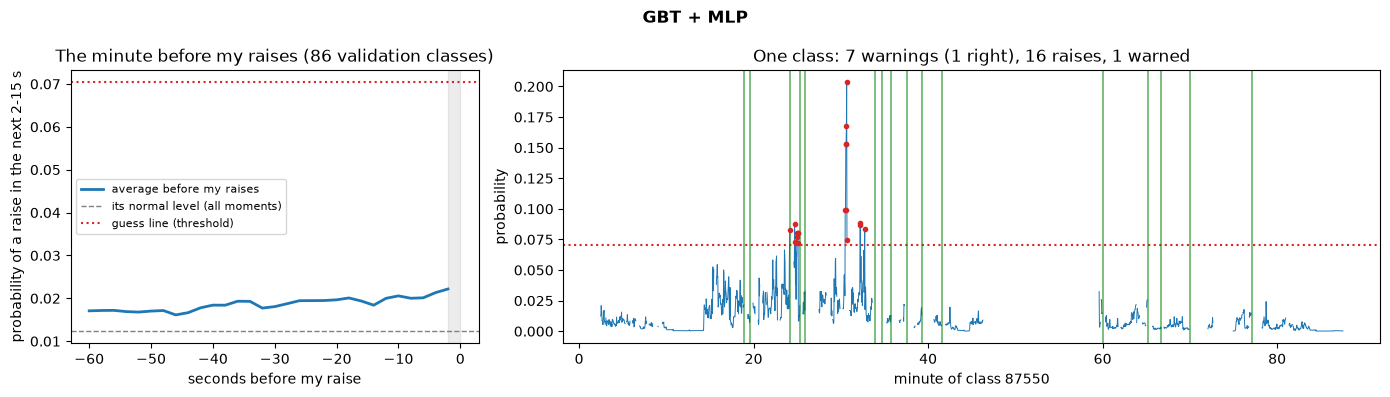

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
GBT + MLP,551,23,528,4.2%,6.4,20 of 504,11,10,14
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [30]:
chosen("gbt_mlp")
show_model("gbt_mlp", va, P_VA["gbt_mlp"], TAU["gbt_mlp"])

**Figure 3.6. GBT + MLP on validation.** As Figure 3.2, for the trees that also see the MLP's
score and the cosine similarities.

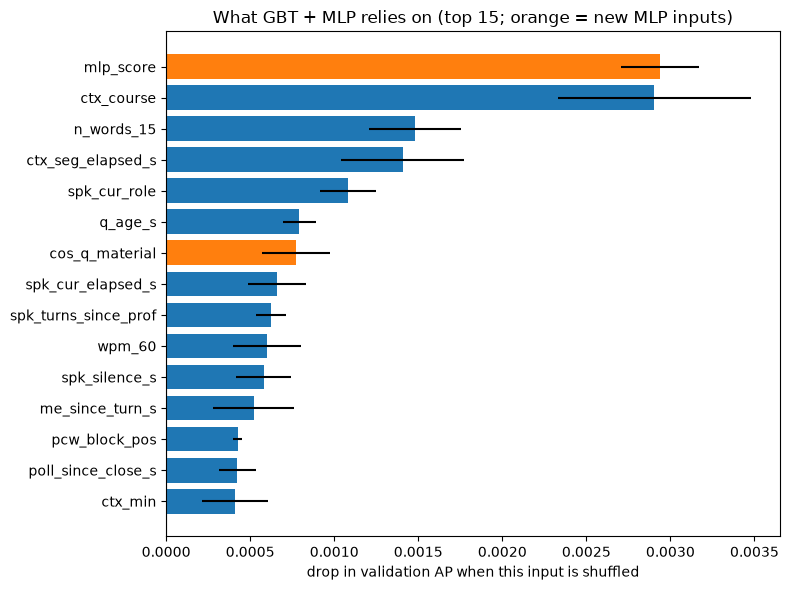

In [31]:
importance_chart(RES["gbt_mlp"], "What GBT + MLP relies on (top 15; orange = new MLP inputs)",
                 highlight=("mlp_score", *flex.COSINES))

**Figure 3.7. What GBT + MLP relies on.** As Figure 3.3; orange bars are the inputs the MLP step
added (its score and the cosine similarities).

### 3.3 TCN (temporal convolutional network)

**The idea.** The trees see one snapshot per moment and the MLP sees sentence vectors; neither
sees the **order** of events. The TCN reads the class as a sequence, one step every 2 s, and
can learn patterns over the last 8.5 minutes: a question, a pause, two students answer, the
professor rephrases, and then I raise.

**What it reads at each 2-s step** (214 numbers, all available at t; built with
`oncue/gru.py`'s tested causal step builders):

| part | numbers |
|---|---|
| what was said in this step: the mean sentence vector of the frames that closed in the last 2 s, compressed by PCA (fitted on train) | 64 + 1 flag |
| seconds of speech in this step per role (professor, me, a student, unknown) | 4 |
| the trees' numeric inputs at t (durations log-scaled, missing values filled + flagged, standardised on train) and one-hot categories (course, area, segment type, current speaker's role, last raise outcome, question kind) | the rest |

Every grid step is kept, also moments that do not count, as context; the loss uses only the
counting moments.

**The model.** Seven causal dilated convolutions (kernel 3, dilations 1, 2, 4, …, 64, 32
channels, dropout 0.2), each with a residual connection, then one output per step. The output
at t sees only the 255 steps up to t (8.5 min), never the future; both limits are tested. The
math is in the write-up (Models, F3). Log loss on counting moments, AdamW (learning rate
0.001, weight decay 0.01), 8
classes per batch, output started at the base rate. Choosing the number of epochs: 5 runs of
15 epochs on all train sessions; the epoch with the best average validation AP is kept. Then in
each of the 4 folds (each with its own PCA and scaling fitted on its own training sessions), 5
runs of that many epochs are averaged.

inputs per step: 214; parameters: 46,113; receptive field: 255 steps (8.5 min); chosen: 4 epochs; 5 runs averaged per fold


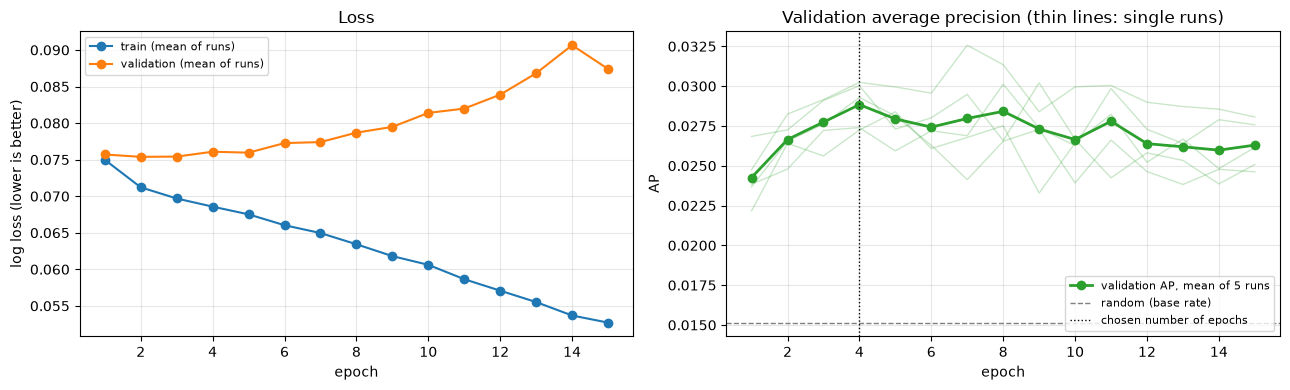

In [32]:
t_ = RES["tcn"]
print(f"inputs per step: {t_['in_dim']}; parameters: {t_['n_params']:,}; receptive field: "
      f"{t_['receptive_field_steps']} steps ({t_['receptive_field_steps'] * 2 / 60:.1f} min); "
      f"chosen: {t_['best_epoch']} epochs; {t_['n_seeds']} runs averaged per fold")
run_curves(t_, "val_ap")

**Figure 3.8. Learning curves of the TCN.** As Figure 3.4: **left**, log loss on train (blue)
and validation (orange), averaged over the 5 runs; **right**, validation AP per epoch (thin
lines: single runs; thick: their average); dotted line: the number of epochs kept.

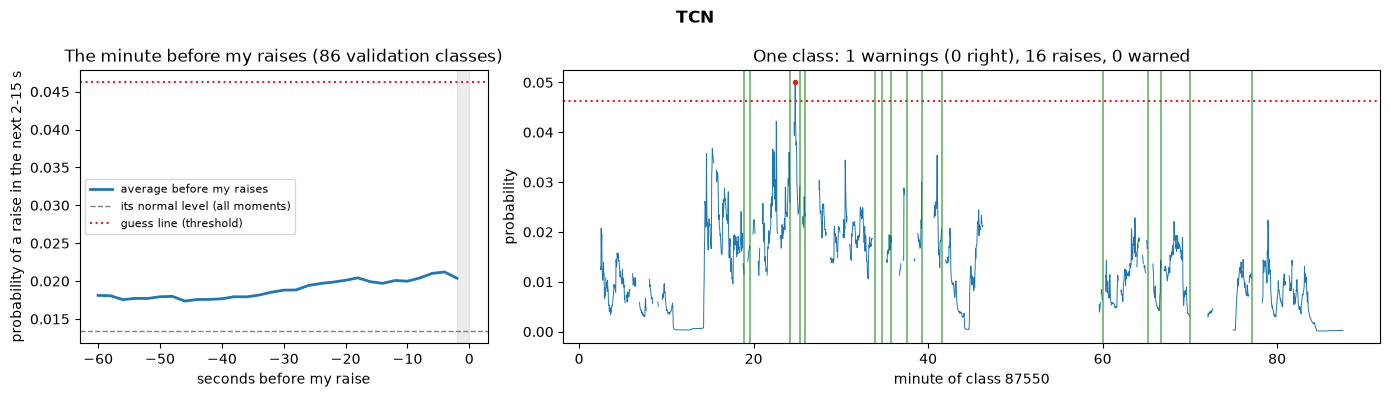

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
TCN,510,24,486,4.7%,5.9,20 of 504,13,15,14
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [33]:
show_model("tcn", va, P_VA["tcn"], TAU["tcn"])

**Figure 3.9. The TCN on its own (validation).** As Figure 3.2, for the TCN's probability alone.

### GBT + MLP + TCN: the trees with both specialists

The trees again, now with the MLP's score, the cosine similarities and the TCN's score (both
scores out-of-fold on train). Same tree sizes, same choice on validation, same out-of-fold
threshold.

chosen on validation: 31 leaves per tree, 180 trees; validation AP of the 4 fold models: 0.0272


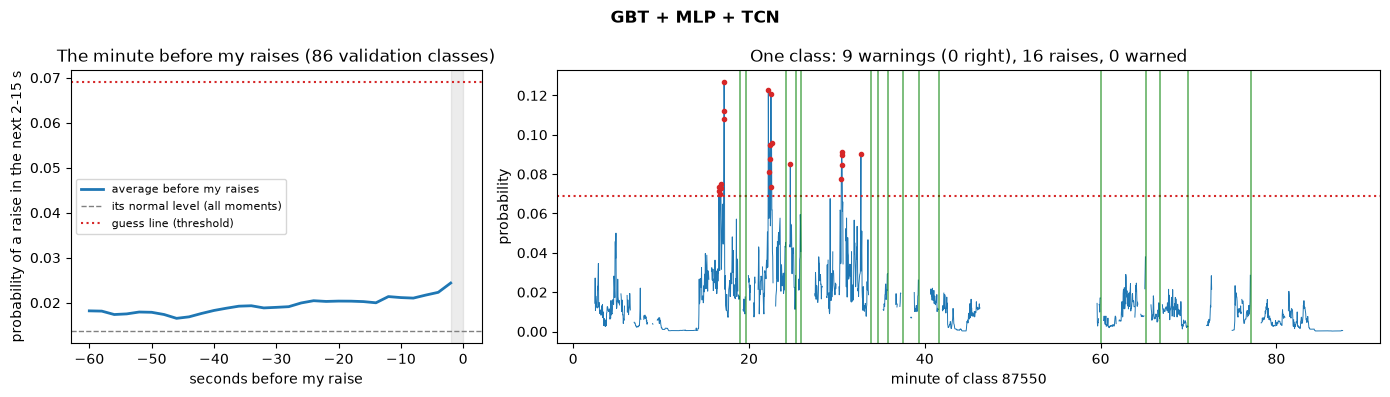

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
GBT + MLP + TCN,569,25,544,4.4%,6.6,21 of 504,13,13,9
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [34]:
chosen("gbt_mlp_tcn")
show_model("gbt_mlp_tcn", va, P_VA["gbt_mlp_tcn"], TAU["gbt_mlp_tcn"])

**Figure 3.10. GBT + MLP + TCN on validation.** As Figure 3.2, for the trees that also see the
MLP's and the TCN's scores.

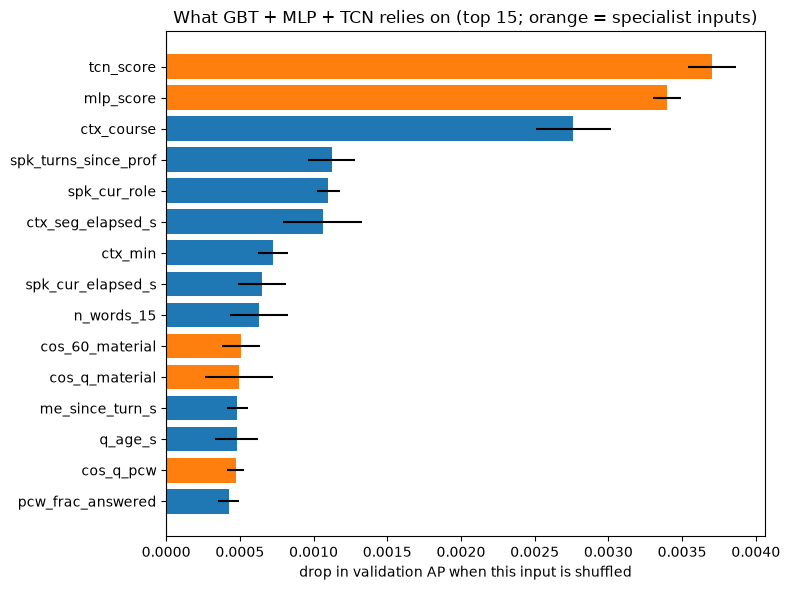

In [35]:
importance_chart(RES["gbt_mlp_tcn"], "What GBT + MLP + TCN relies on (top 15; orange = specialist inputs)",
                 highlight=("mlp_score", "tcn_score", *flex.COSINES))

**Figure 3.11. What GBT + MLP + TCN relies on.** As Figure 3.3; orange bars are the inputs the
specialists added (the MLP's and the TCN's scores and the cosine similarities).

### 3.4 Without the trees: simpler combiners

Do we need the trees at the end? Two simpler ways to combine the same specialists, trained and
scored exactly like the trees (out-of-fold on train, one fold model per validation session):

* **MLP + TCN, no trees:** a logistic regression on just the two specialists' scores (the
  math is in the write-up, Models, F5).
* **Logistic combiner (all inputs):** a logistic regression on everything GBT + MLP + TCN sees
  (the 68 inputs, the 7 cosines and the two specialist scores; durations log-scaled, missing
  values filled and flagged, standardised, categories one-hot). Its L2 penalty is chosen on
  validation (C = 0.01, 0.1 or 1).

MLP + TCN, no trees (logistic): 2 inputs, C = 0.01; validation AP of the fold models 0.0310
Logistic combiner (all inputs): 77 inputs, C = 0.01; validation AP of the fold models 0.0297


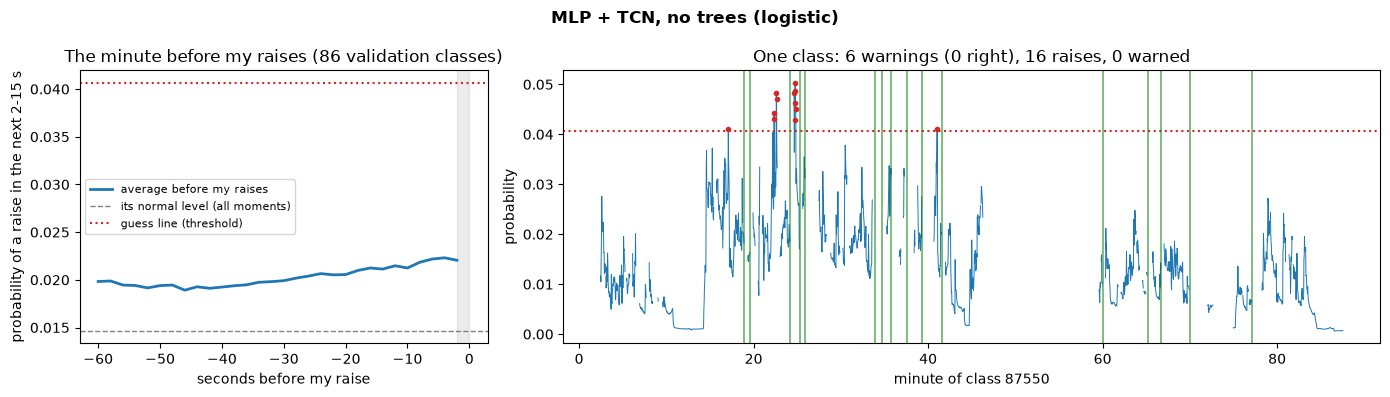

,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
"MLP + TCN, no trees (logistic)",651,36,615,5.5%,7.6,31 of 504,22,22,15
A perfect model (ceiling),334,334,0,100.0%,3.9,326 of 504,315,296,270


In [36]:
for k in ("mlp_tcn_lr", "lr_all"):
    print(f"{NAME[k]}: {len(RES[k]['inputs'])} inputs, C = {RES[k]['C']}; "
          f"validation AP of the fold models {average_precision_score(va['y'], P_VA[k]):.4f}")
show_model("mlp_tcn_lr", va, P_VA["mlp_tcn_lr"], TAU["mlp_tcn_lr"])

**Figure 3.12. MLP + TCN with no trees (validation).** As Figure 3.2, for a logistic regression
on the two specialists' scores alone.

### 3.5 So far: naive vs flexible (validation), with error bars

**Within-class AP comes first:** it answers "in this session, does the model know when?". Each
AP is also shown as **× random** (a model with no information: AP = the share of positives,
0.015 pooled; AP_w = each session's share, weighted, 0.022 here).

**Error bars: a session bootstrap.** The 86 validation sessions are resampled with replacement
1,000 times and every model is rescored on each resample (the same resamples for all models,
so differences are paired). The 95% interval is the middle 95% of those scores. For each model
we also show how much the best model (by AP_w) beats it, with a 95% interval, and in what
share of resamples it wins: a gap whose interval includes 0 may be luck.

In [37]:
from oncue import metrics as ometrics
ORDER = ["R", "QT", "NB", "TFIDF", "gbt", "mlp", "gbt_mlp", "tcn", "gbt_mlp_tcn", "mlp_tcn_lr", "lr_all"]
ci = BOOT["ci"]
rand_ap = va["y"].mean()
rand_apw = ometrics.ap_within(va["y"].to_numpy(), np.full(len(va), 0.5), va["class_id"].to_numpy())
rows = {}
for i in ORDER:
    pm = baselines.point_metrics(va, P_VA[i])
    rows[NAME[i]] = {"AP_w": round(pm["AP_w"], 4), "AP_w × random": round(pm["AP_w"] / rand_apw, 1),
                     "AP_w 95% interval": f"{ci.loc[i, 'AP_w low']:.3f}-{ci.loc[i, 'AP_w high']:.3f}",
                     "AP": round(pm["AP"], 4), "AP × random": round(pm["AP"] / rand_ap, 1),
                     "AP 95% interval": f"{ci.loc[i, 'AP low']:.3f}-{ci.loc[i, 'AP high']:.3f}",
                     "ROC AUC": round(pm["ROC_AUC"], 3), **guess_row(va, P_VA[i], TAU[i])}
rows["A perfect model (ceiling)"] = {"AP_w": 1.0, "AP": 1.0, "ROC AUC": 1.0, **perfect_row(va)}
display(Markdown(f"**Validation, all models so far** (random: AP_w {rand_apw:.3f}, AP {rand_ap:.3f}; "
                 "warnings at each model's threshold, set on its out-of-fold train scores)"))
display(pd.DataFrame(rows).T.fillna(""))
ref = BOOT["ref"]
d = BOOT["diff"].loc[[i for i in ORDER if i != ref]]
tab = pd.DataFrame({
    "AP_w gain of the best": [f"{g:+.4f} ({lo:+.4f} to {hi:+.4f})" for g, lo, hi in zip(d["AP_w gain"], d["AP_w low"], d["AP_w high"])],
    "best wins (AP_w)": [f"{100 * w:.0f}% of resamples" for w in d["AP_w: ref better in"]],
    "AP gain of the best": [f"{g:+.4f} ({lo:+.4f} to {hi:+.4f})" for g, lo, hi in zip(d["AP gain"], d["AP low"], d["AP high"])],
    "best wins (AP)": [f"{100 * w:.0f}% of resamples" for w in d["AP: ref better in"]]},
    index=[NAME[i] for i in d.index])
display(Markdown(f"**Is the best model ({NAME[ref]}, by AP_w) really better?** Paired session bootstrap, "
                 f"{BOOT['B']:,} resamples: mean gain (95% interval)"))
display(tab)

**Validation, all models so far** (random: AP_w 0.022, AP 0.015; warnings at each model's threshold, set on its out-of-fold train scores)

,AP_w,AP_w × random,AP_w 95% interval,AP,AP × random,AP 95% interval,ROC AUC,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Professor-question rule,0.0502,2.3,0.041-0.060,0.0245,1.6,0.020-0.030,0.599,1276,43,1233,3.4%,14.8,37 of 504,19,18,13
Question timing (LR),0.0493,2.2,0.039-0.062,0.0231,1.5,0.019-0.030,0.588,431,27,404,6.3%,5.0,24 of 504,19,15,13
Naive Bayes (words),0.037,1.7,0.026-0.049,0.0174,1.2,0.014-0.023,0.507,25,1,24,4.0%,0.3,1 of 504,1,1,0
TF-IDF + LR (words),0.0516,2.3,0.039-0.066,0.0242,1.6,0.020-0.029,0.658,207,11,196,5.3%,2.4,10 of 504,8,6,6
GBT (trees),0.0532,2.4,0.043-0.064,0.0261,1.7,0.022-0.032,0.683,233,9,224,3.9%,2.7,8 of 504,5,5,6
Content-alignment MLP,0.0569,2.6,0.045-0.068,0.027,1.8,0.022-0.033,0.658,572,40,532,7.0%,6.7,36 of 504,23,22,24
GBT + MLP,0.0574,2.6,0.044-0.075,0.0273,1.8,0.023-0.036,0.691,551,23,528,4.2%,6.4,20 of 504,11,10,14
TCN,0.0573,2.6,0.046-0.068,0.0277,1.8,0.023-0.033,0.688,510,24,486,4.7%,5.9,20 of 504,13,15,14
GBT + MLP + TCN,0.0581,2.6,0.047-0.070,0.0272,1.8,0.022-0.033,0.686,569,25,544,4.4%,6.6,21 of 504,13,13,9
"MLP + TCN, no trees (logistic)",0.0734,3.3,0.058-0.090,0.031,2.0,0.025-0.040,0.699,651,36,615,5.5%,7.6,31 of 504,22,22,15


**Is the best model (MLP + TCN, no trees (logistic), by AP_w) really better?** Paired session bootstrap, 1,000 resamples: mean gain (95% interval)

,AP_w gain of the best,best wins (AP_w),AP gain of the best,best wins (AP)
Professor-question rule,+0.0230 (+0.0094 to +0.0384),100% of resamples,+0.0068 (+0.0010 to +0.0143),99% of resamples
Question timing (LR),+0.0240 (+0.0089 to +0.0408),100% of resamples,+0.0078 (+0.0010 to +0.0153),98% of resamples
Naive Bayes (words),+0.0365 (+0.0182 to +0.0562),100% of resamples,+0.0139 (+0.0066 to +0.0226),100% of resamples
TF-IDF + LR (words),+0.0216 (+0.0066 to +0.0386),100% of resamples,+0.0073 (+0.0015 to +0.0148),100% of resamples
GBT (trees),+0.0200 (+0.0070 to +0.0364),100% of resamples,+0.0052 (+0.0009 to +0.0114),99% of resamples
Content-alignment MLP,+0.0165 (+0.0046 to +0.0302),100% of resamples,+0.0044 (+0.0010 to +0.0096),99% of resamples
GBT + MLP,+0.0158 (-0.0024 to +0.0343),96% of resamples,+0.0037 (-0.0012 to +0.0093),93% of resamples
TCN,+0.0162 (+0.0051 to +0.0275),100% of resamples,+0.0037 (+0.0005 to +0.0087),99% of resamples
GBT + MLP + TCN,+0.0151 (-0.0008 to +0.0331),97% of resamples,+0.0042 (-0.0002 to +0.0100),97% of resamples
Logistic combiner (all inputs),+0.0088 (-0.0064 to +0.0227),89% of resamples,+0.0014 (-0.0031 to +0.0057),77% of resamples


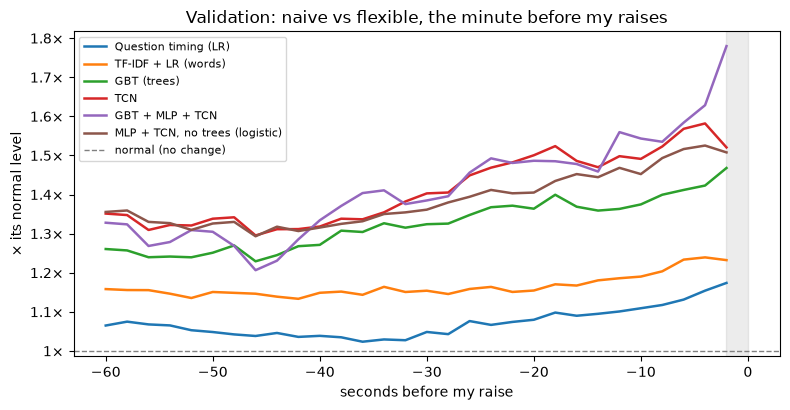

In [38]:
all_together(va, P_VA, ["QT", "TFIDF", "gbt", "tcn", "gbt_mlp_tcn", "mlp_tcn_lr"],
             "Validation: naive vs flexible, the minute before my raises")

**Figure 3.13. Naive vs flexible before my raises (validation).** As Figure 2.5 (each model's
probability divided by its own normal level; 1× = notices nothing), for the two best naive
models and the main flexible ones.

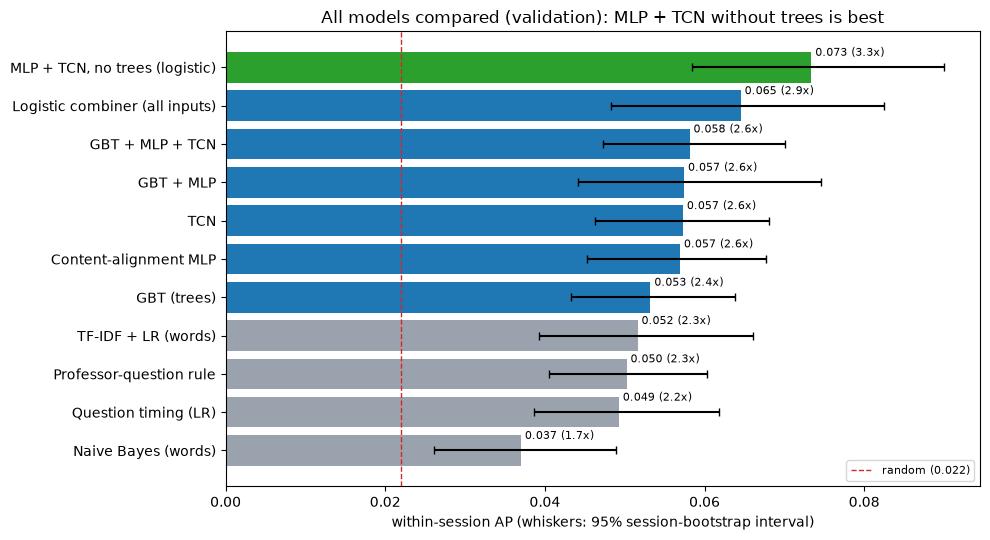

In [39]:
def compare_bars(ax, ids, value, ci_, rnd, title):
    vals = [value(i) for i in ids]
    lo = [v - ci_.loc[i, "AP_w low"] for v, i in zip(vals, ids)]
    hi = [ci_.loc[i, "AP_w high"] - v for v, i in zip(vals, ids)]
    cols = ["tab:green" if i == "mlp_tcn_lr" else ("#9aa3ad" if i in ("R", "QT", "NB", "TFIDF") else "tab:blue")
            for i in ids]
    ax.barh([NAME[i] for i in ids], vals, xerr=[lo, hi], color=cols, capsize=3)
    for k, v in enumerate(vals):
        ax.text(v, k + 0.3, f" {v:.3f} ({v / rnd:.1f}x)", fontsize=8)
    ax.axvline(rnd, color="tab:red", ls="--", lw=1, label=f"random ({rnd:.3f})")
    ax.set(xlabel="within-session AP (whiskers: 95% session-bootstrap interval)", title=title)
    ax.legend(fontsize=8, loc="lower right")

ALL_IDS = ["NB", "QT", "R", "TFIDF", "gbt", "mlp", "tcn", "gbt_mlp", "gbt_mlp_tcn", "lr_all", "mlp_tcn_lr"]
fig, ax = plt.subplots(figsize=(10, 5.5))
compare_bars(ax, ALL_IDS, lambda i: ometrics.ap_within(va["y"].to_numpy(), P_VA[i], va["class_id"].to_numpy()),
             BOOT["ci"], rand_apw, "All models compared (validation): MLP + TCN without trees is best")
plt.tight_layout(); plt.show()

**Figure 3.14. All models compared (validation).** Within-session AP of every model, with its 95%
session-bootstrap interval; the red dashed line is a model with no information. Grey: naive
models; blue: flexible models and combinations; green: MLP + TCN without trees, the best, ahead of
every other model in 89-100% of paired resamples (table above).

In [40]:
best = BOOT["ref"]
rel = flex.reliability(va["y"].to_numpy(), RES[best]["val_cal"])
display(Markdown(f"**Are {NAME[best]}'s probabilities honest?** After Platt scaling on its out-of-fold "
                 "train scores (a monotone rescaling: it changes no ranking and no warning), the mean "
                 "predicted probability in each band against the share of moments that really were "
                 "followed by a raise (validation)"))
display(rel.style.format({"mean predicted": "{:.2%}", "observed": "{:.2%}"}))

**Are MLP + TCN, no trees (logistic)'s probabilities honest?** After Platt scaling on its out-of-fold train scores (a monotone rescaling: it changes no ranking and no warning), the mean predicted probability in each band against the share of moments that really were followed by a raise (validation)

,moments,mean predicted,observed
bin,,,
"(-0.001, 0.01]",43625,0.50%,0.57%
"(0.01, 0.02]",42330,1.47%,1.43%
"(0.02, 0.04]",29911,2.64%,2.87%
"(0.04, 0.08]",1505,4.54%,4.65%
"(0.08, 1.0]",1,8.08%,0.00%


**The final pipeline: MLP + TCN without trees.** Chosen on validation (best AP_w and AP, and the
simplest), and declared, with the test headline, before test was scored.

### 3.6 How the final pipeline learned (validation)

The final pipeline learns through its two specialists (the logistic combiner on top has only two
weights). To watch it learn, the specialists' fold models are retrained exactly as in the final
run (same folds, settings and seeds) for 15 epochs. After every epoch each run scores its
held-out train sessions and its validation sessions, and the two scores are combined as the final
pipeline does. At the 4 epochs actually used this reproduces the final pipeline exactly.
Validation only: test is not touched.

epoch 4 reproduces the final pipeline: validation AP_w 0.0734 (saved run 0.0734; correlation of the scores 1.0000)


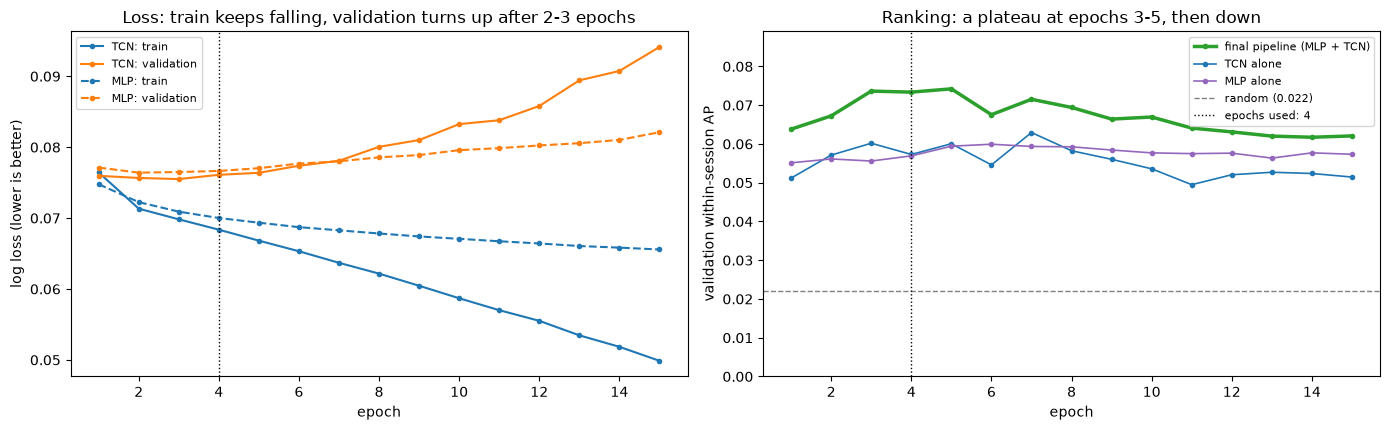

epoch,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
final_AP_w,0.0638,0.0672,0.0736,0.0734,0.0742,0.0676,0.0715,0.0694,0.0664,0.0669,0.0641,0.0631,0.0620,0.0617,0.0621
final_AP,0.0294,0.0304,0.0314,0.0310,0.0335,0.0310,0.0315,0.0304,0.0304,0.0282,0.0292,0.0280,0.0279,0.0280,0.0266
tcn_AP_w,0.0512,0.0571,0.0602,0.0573,0.0601,0.0546,0.0629,0.0582,0.0560,0.0536,0.0495,0.0521,0.0527,0.0524,0.0515
mlp_AP_w,0.0551,0.0561,0.0556,0.0569,0.0594,0.0599,0.0594,0.0593,0.0584,0.0577,0.0575,0.0576,0.0564,0.0577,0.0573
tcn_train_loss,0.0764,0.0713,0.0698,0.0684,0.0668,0.0653,0.0637,0.0622,0.0605,0.0587,0.0570,0.0555,0.0535,0.0518,0.0499
tcn_val_loss,0.0760,0.0757,0.0755,0.0761,0.0764,0.0774,0.0781,0.0801,0.0810,0.0833,0.0838,0.0858,0.0894,0.0908,0.0941
mlp_train_loss,0.0748,0.0723,0.0709,0.0700,0.0694,0.0687,0.0683,0.0678,0.0674,0.0671,0.0667,0.0664,0.0661,0.0658,0.0656
mlp_val_loss,0.0771,0.0764,0.0765,0.0766,0.0770,0.0777,0.0780,0.0786,0.0789,0.0796,0.0799,0.0802,0.0806,0.0810,0.0821


In [41]:
RUN_LEARNING = False             # True: rerun it (python -m oncue flex --step learning, about 10 min)
if RUN_LEARNING or not (DATA_DIR / "results" / "flex" / "learning.pkl").exists():
    subprocess.run([sys.executable, "-m", "oncue", "flex", "--step", "learning"], check=True)
LRN = flex.load_result("learning")
cur, E_ = LRN["curve"], LRN["chosen_epoch"]
print(f"epoch {E_} reproduces the final pipeline: validation AP_w {LRN['repro']['AP_w_here']:.4f} "
      f"(saved run {LRN['repro']['AP_w_saved']:.4f}; correlation of the scores {LRN['repro']['corr']:.4f})")
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.4))
for m_, lab, ls in (("tcn", "TCN", "-"), ("mlp", "MLP", "--")):
    a.plot(cur["epoch"], cur[f"{m_}_train_loss"], ls=ls, color="tab:blue", marker="o", ms=3, label=f"{lab}: train")
    a.plot(cur["epoch"], cur[f"{m_}_val_loss"], ls=ls, color="tab:orange", marker="o", ms=3, label=f"{lab}: validation")
a.axvline(E_, color="k", ls=":", lw=1)
a.set(xlabel="epoch", ylabel="log loss (lower is better)",
      title="Loss: train keeps falling, validation turns up after 2-3 epochs")
a.legend(fontsize=8)
for col, lab, c_, lw in (("final_AP_w", "final pipeline (MLP + TCN)", "tab:green", 2.5),
                         ("tcn_AP_w", "TCN alone", "tab:blue", 1.2), ("mlp_AP_w", "MLP alone", "tab:purple", 1.2)):
    b.plot(cur["epoch"], cur[col], color=c_, lw=lw, marker="o", ms=3, label=lab)
b.axhline(rand_apw, color="grey", ls="--", lw=1, label=f"random ({rand_apw:.3f})")
b.axvline(E_, color="k", ls=":", lw=1, label=f"epochs used: {E_}")
b.set(xlabel="epoch", ylabel="validation within-session AP", title="Ranking: a plateau at epochs 3-5, then down",
      ylim=(0, cur["final_AP_w"].max() * 1.2))
b.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(cur[["epoch", "final_AP_w", "final_AP", "tcn_AP_w", "mlp_AP_w", "tcn_train_loss", "tcn_val_loss",
             "mlp_train_loss", "mlp_val_loss"]].round(4).set_index("epoch").T)

**Figure 3.15. How the final pipeline learned (validation).** **Left:** log loss of the two
specialists after each epoch, on the sessions they train on (blue) and on validation (orange);
solid = TCN, dashed = MLP; each point is the mean of 4 folds x 5 runs. Train loss keeps falling
while validation loss turns up after 2-3 epochs: from there on the models memorise the train
sessions. **Right:** validation within-session AP after each epoch, for the final pipeline
(the two specialists combined, green) and each specialist alone. The dotted line marks the 4
epochs used, chosen beforehand from each specialist's own validation curve.

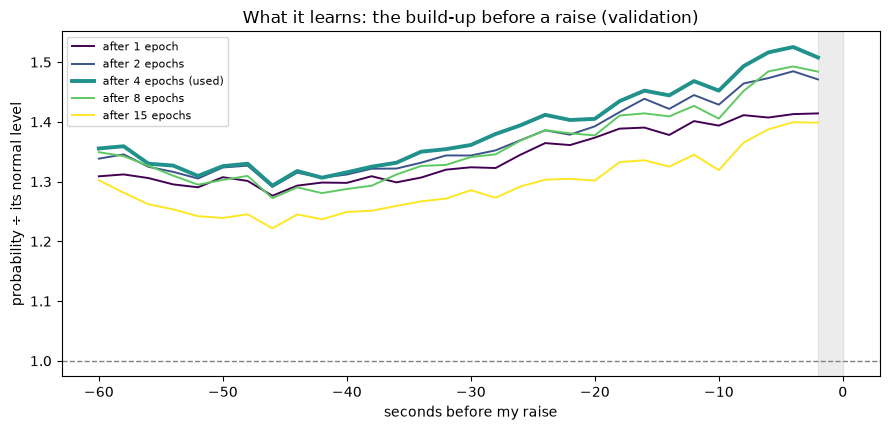

In [42]:
EPS = (1, 2, 4, 8, 15)
fig, ax = plt.subplots(figsize=(9, 4.4))
cm_ = plt.get_cmap("viridis")
for j, e in enumerate(EPS):
    p_e = LRN["final_val"][e - 1].astype(float)
    pr = baselines.peri_raise(va, p_e, raises)
    ax.plot(pr["offset_s"], pr["mean_p"] / p_e.mean(), color=cm_(j / (len(EPS) - 1)), lw=2.8 if e == E_ else 1.4,
            label=f"after {e} epoch{'s' if e > 1 else ''}" + (" (used)" if e == E_ else ""))
ax.axhline(1, color="grey", ls="--", lw=1)
ax.axvspan(-2, 0, color="grey", alpha=0.15)
ax.set(xlabel="seconds before my raise", ylabel="probability ÷ its normal level",
       title="What it learns: the build-up before a raise (validation)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 3.16. What the final pipeline learns, epoch by epoch (validation).** Its average
probability in the minute before my raises, divided by its own average over all moments (1x =
notices nothing), after 1, 2, 4, 8 and 15 epochs of the specialists. After one epoch it is
already higher before raises; by epoch 4 the climb into the last seconds is steepest; by epoch
15 it has flattened again, as the models trade the general pattern for details of the train
sessions. The grey band is the last 2 s, which no warning can use.

### 3.7 Test: the final pipeline, scored once

**Declared before test was scored (18 Oct, 21:51):** the final pipeline is MLP + TCN without
trees; the headline is within-session AP (AP_w) with its 95% session-bootstrap interval, with
AP alongside. Nothing below changes any model, setting or threshold. Only the fold models'
scores had been saved, so the same fold models are retrained with the same settings and seeds
to score test (each test session by one fold model, as validation); rescoring validation the
same way checks that they reproduce.

In [43]:
RUN_TEST = False                 # test was scored once: python -m oncue flex --step test
if RUN_TEST or not (DATA_DIR / "results" / "flex" / "test_bootstrap.pkl").exists():
    subprocess.run([sys.executable, "-m", "oncue", "flex", "--step", "test"], check=True)
T, TB = flex.load_result("test_final"), flex.load_result("test_bootstrap")
display(Markdown("**Reproducibility check:** validation rescored by the retrained fold models"))
display(pd.DataFrame({"saved run": [T["repro"]["val_AP_w_saved"]], "retrained": [T["repro"]["val_AP_w_rescored"]],
                      "correlation of the two sets of scores": [T["repro"]["val_corr"]]},
                     index=["validation AP_w, MLP + TCN"]).round(4))

P_TE.update({"mlp": T["mlp_test"], "tcn": T["tcn_test"], "mlp_tcn_lr": T["test"]})
TEST_IDS = ["R", "QT", "NB", "TFIDF", "mlp", "tcn", "mlp_tcn_lr"]
rows = {}
for i in TEST_IDS:
    pt, ci_ = TB["point"][i], TB["ci"].loc[i]
    rows[NAME[i]] = {"AP_w": round(pt["AP_w"], 4), "AP_w × random": round(pt["AP_w"] / TB["random_AP_w"], 1),
                     "AP_w 95% interval": f"{ci_['AP_w low']:.3f}-{ci_['AP_w high']:.3f}",
                     "AP": round(pt["AP"], 4), "AP × random": round(pt["AP"] / TB["random_AP"], 1),
                     "AP 95% interval": f"{ci_['AP low']:.3f}-{ci_['AP high']:.3f}",
                     **guess_row(te, P_TE[i], TAU[i])}
rows["A perfect model (ceiling)"] = {"AP_w": 1.0, "AP": 1.0, **perfect_row(te)}
display(Markdown(f"**Test, 86 sessions** (random: AP_w {TB['random_AP_w']:.3f}, AP {TB['random_AP']:.3f}; "
                 "thresholds frozen: naive from train, flexible from out-of-fold train scores)"))
display(pd.DataFrame(rows).T.fillna(""))
d = TB["diff"].loc[[i for i in TEST_IDS if i != TB["ref"]]]
display(Markdown(f"**Does the final pipeline really beat them on test?** Paired session bootstrap, {TB['B']:,} resamples"))
display(pd.DataFrame({
    "AP_w gain of the final pipeline": [f"{g:+.4f} ({lo:+.4f} to {hi:+.4f})" for g, lo, hi in zip(d["AP_w gain"], d["AP_w low"], d["AP_w high"])],
    "final wins (AP_w)": [f"{100 * w:.0f}% of resamples" for w in d["AP_w: ref better in"]],
    "AP gain": [f"{g:+.4f} ({lo:+.4f} to {hi:+.4f})" for g, lo, hi in zip(d["AP gain"], d["AP low"], d["AP high"])],
    "final wins (AP)": [f"{100 * w:.0f}% of resamples" for w in d["AP: ref better in"]]},
    index=[NAME[i] for i in d.index]))

**Reproducibility check:** validation rescored by the retrained fold models

,saved run,retrained,correlation of the two sets of scores
"validation AP_w, MLP + TCN",0.0734,0.0734,1.0


**Test, 86 sessions** (random: AP_w 0.025, AP 0.015; thresholds frozen: naive from train, flexible from out-of-fold train scores)

,AP_w,AP_w × random,AP_w 95% interval,AP,AP × random,AP 95% interval,warnings,right,wrong,% right,warnings per class,raises warned (a guess 2-15 s ahead),a guess 2-5 s ahead (ideal),a guess 5-10 s ahead,a guess 10-15 s ahead
Professor-question rule,0.051,2.1,0.043-0.058,0.0246,1.6,0.020-0.031,1537,50,1487,3.3%,17.9,46 of 533,15,23,16
Question timing (LR),0.0632,2.5,0.049-0.077,0.0263,1.7,0.020-0.034,505,35,470,6.9%,5.9,30 of 533,19,15,19
Naive Bayes (words),0.0483,1.9,0.036-0.063,0.0196,1.3,0.015-0.026,21,1,20,4.8%,0.2,1 of 533,0,1,0
TF-IDF + LR (words),0.0609,2.5,0.049-0.073,0.0268,1.8,0.021-0.034,267,12,255,4.5%,3.1,11 of 533,9,9,6
Content-alignment MLP,0.0569,2.3,0.045-0.069,0.0252,1.7,0.021-0.031,312,16,296,5.1%,3.6,15 of 533,5,10,8
TCN,0.0712,2.9,0.056-0.087,0.0336,2.2,0.026-0.044,565,35,530,6.2%,6.6,34 of 533,22,26,24
"MLP + TCN, no trees (logistic)",0.0758,3.0,0.059-0.096,0.0354,2.3,0.027-0.047,553,37,516,6.7%,6.4,35 of 533,17,24,22
A perfect model (ceiling),1.0,,,1.0,,,323,323,0,100.0%,3.8,322 of 533,314,309,290


**Does the final pipeline really beat them on test?** Paired session bootstrap, 1,000 resamples

,AP_w gain of the final pipeline,final wins (AP_w),AP gain,final wins (AP)
Professor-question rule,+0.0248 (+0.0101 to +0.0408),100% of resamples,+0.0114 (+0.0047 to +0.0202),100% of resamples
Question timing (LR),+0.0125 (-0.0028 to +0.0324),93% of resamples,+0.0097 (+0.0026 to +0.0182),100% of resamples
Naive Bayes (words),+0.0271 (+0.0079 to +0.0484),100% of resamples,+0.0161 (+0.0088 to +0.0249),100% of resamples
TF-IDF + LR (words),+0.0150 (-0.0044 to +0.0354),93% of resamples,+0.0089 (+0.0021 to +0.0171),100% of resamples
Content-alignment MLP,+0.0187 (+0.0073 to +0.0308),100% of resamples,+0.0106 (+0.0051 to +0.0185),100% of resamples
TCN,+0.0043 (-0.0054 to +0.0148),80% of resamples,+0.0018 (-0.0019 to +0.0055),85% of resamples


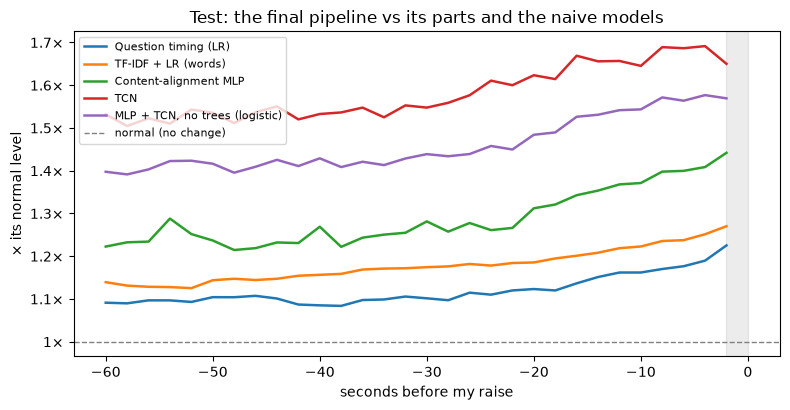

In [44]:
all_together(te, P_TE, ["QT", "TFIDF", "mlp", "tcn", "mlp_tcn_lr"], "Test: the final pipeline vs its parts and the naive models")

**Figure 3.17. The final pipeline on test, before my raises.** As Figure 2.5, on the 86 test
sessions: each model's probability in the minute before my raises, divided by its own normal
level (1× = notices nothing), for the two best naive models, the two specialists and the final
pipeline (MLP + TCN without trees).

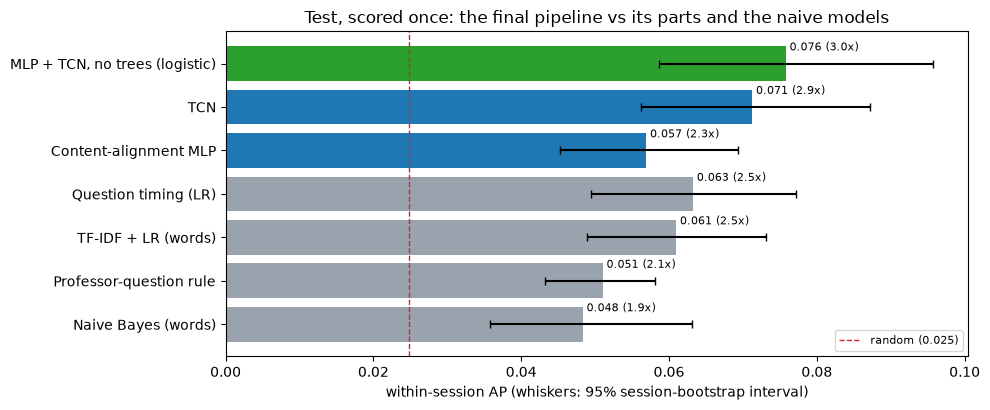

In [45]:
fig, ax = plt.subplots(figsize=(10, 4.2))
compare_bars(ax, ["NB", "R", "TFIDF", "QT", "mlp", "tcn", "mlp_tcn_lr"], lambda i: TB["point"][i]["AP_w"],
             TB["ci"], TB["random_AP_w"], "Test, scored once: the final pipeline vs its parts and the naive models")
plt.tight_layout(); plt.show()

**Figure 3.18. Test, scored once.** Within-session AP on the 86 test sessions with 95%
session-bootstrap intervals, for the frozen naive models, the two specialists and the final
pipeline (green). The tree models were dropped on validation and were never scored on test.

### 3.8 One test session, start to end

What the final pipeline does in a real class it never saw. To avoid picking a flattering
example, the session is chosen by a fixed rule: among the test sessions with at least 5 of my
raises, the one with the **median** within-session AP (a typical session, not the best).

45 test sessions with >= 5 raises; median within-session AP 0.053 (session 86380)


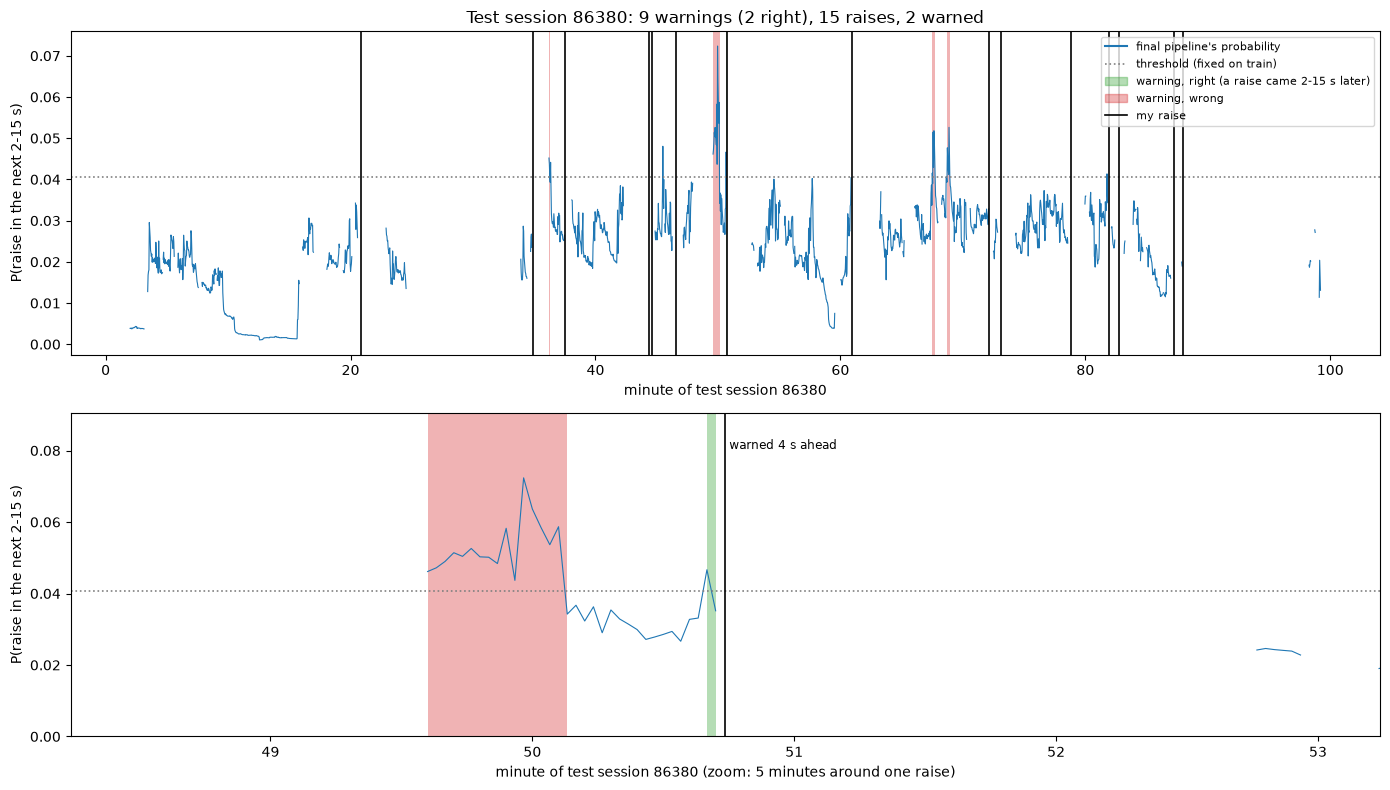

In [46]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

FIN = "mlp_tcn_lr"
from sklearn.metrics import average_precision_score
n_r = raises[raises["class_id"].isin(te["class_id"])].groupby("class_id").size()
ap_s = {c: average_precision_score(te["y"].to_numpy()[ix], P_TE["mlp_tcn_lr"][ix])
        for c, ix in te.groupby("class_id").indices.items() if n_r.get(c, 0) >= 5 and te["y"].to_numpy()[ix].any()}
order = sorted(ap_s, key=ap_s.get)
EXT = int(order[len(order) // 2])           # the median session
print(f"{len(order)} test sessions with >= 5 raises; median within-session AP {ap_s[EXT]:.3f} (session {EXT})")
m_ = (te["class_id"] == EXT).to_numpy()
ct, pt_, tau_ = te[m_], P_TE[FIN][m_], TAU[FIN]
t_, y_ = ct["t_s"].to_numpy(float), ct["y"].to_numpy().astype(bool)
on_ = np.sort(raises.loc[raises["class_id"] == EXT, "onset_s"].to_numpy())
said_ = pt_ >= tau_

# warnings = unbroken runs of yes moments; right if a raise came 2-15 s after one of them
runs, start = [], None
for k in range(len(t_)):
    cont = start is not None and said_[k] and t_[k] - t_[k - 1] <= 2.0 + 1e-6
    if said_[k] and not cont:
        if start is not None:
            runs.append((start, k - 1))
        start = k
    elif not said_[k] and start is not None:
        runs.append((start, k - 1)); start = None
if start is not None:
    runs.append((start, len(t_) - 1))
right_ = [bool(y_[a:b + 1].any()) for a, b in runs]
leads = {}
for o in on_:
    w = t_[said_ & (t_ >= o - 15) & (t_ < o - 2)]
    if len(w):
        leads[o] = o - w.min()

def timeline(ax, lo=None, hi=None):
    x, yq = with_gaps(t_, pt_)
    ax.plot(x / 60, yq, lw=0.8, color="tab:blue")
    ax.axhline(tau_, color="grey", ls=":", lw=1.2)
    for (a, b), ok in zip(runs, right_):
        ax.axvspan(t_[a] / 60, (t_[b] + 2) / 60, color="tab:green" if ok else "tab:red", alpha=0.35, lw=0)
    for o in on_:
        ax.axvline(o / 60, color="black", lw=1.2)
        if lo is not None and lo <= o <= hi:
            txt = f"warned {leads[o]:.0f} s ahead" if o in leads else "not warned"
            ax.text(o / 60, ax.get_ylim()[1] * 0.92, " " + txt, fontsize=8.5, va="top")
    if lo is not None:
        ax.set_xlim(lo / 60, hi / 60)
    ax.set(ylabel="P(raise in the next 2-15 s)")

fig, (a, b) = plt.subplots(2, 1, figsize=(14, 8))
timeline(a)
a.set(xlabel=f"minute of test session {EXT}",
      title=f"Test session {EXT}: {len(runs)} warnings ({sum(right_)} right), {len(on_)} raises, {len(leads)} warned")
focus = min(leads, key=lambda o: abs(leads[o] - 3.5)) if leads else on_[len(on_) // 2]
lo, hi = focus - 150, focus + 150
b.set_ylim(0, max(pt_[(t_ >= lo) & (t_ <= hi)].max() * 1.25, tau_ * 1.5))
timeline(b, lo, hi)
b.set(xlabel=f"minute of test session {EXT} (zoom: 5 minutes around one raise)")
handles = [Line2D([0], [0], color="tab:blue", lw=1.5, label="final pipeline's probability"),
           Line2D([0], [0], color="grey", ls=":", lw=1.2, label="threshold (fixed on train)"),
           Patch(color="tab:green", alpha=0.35, label="warning, right (a raise came 2-15 s later)"),
           Patch(color="tab:red", alpha=0.35, label="warning, wrong"),
           Line2D([0], [0], color="black", lw=1.2, label="my raise")]
a.legend(handles=handles, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

**Figure 3.19. The final pipeline through one typical test session.** **Top:** the whole
session (the median within-session AP among test sessions with at least 5 raises). Blue: the final pipeline's probability at each
counting moment (gaps = moments that do not count: my hand up, me speaking, breakouts); grey
dotted: its threshold, fixed on the train scores; shaded spans: its warnings (an unbroken run
of moments above the threshold), green when my hand went up 2-15 s after one of their moments
and red when it did not; black lines: my raises. **Bottom:** five minutes around one warned
raise, with how far ahead each raise in the window was warned.